# Idea 1 (v2): balanced in-band fine-tuning of the tandem inverse model (13-17 GHz)
Kaggle notebook. Based on Gupta et al., "Tandem Neural Network based Design of Multi-band Antennas" (IEEE TAP 2023).

**Problem.** The paper says the dataset is unbalanced (only ~180k of 500k designs resonate, and the resonances are not spread evenly over 10-20 GHz) and that the tandem network fails to produce single-band antennas where the data is sparse (Sec. IV-A, Fig. 3d vs Fig. 9).

**Idea 1.** Fine-tune your already fine-tuned inverse model on a **balanced subset of real designs that resonate inside 13-17 GHz**, with a **decaying learning rate**, keeping the forward model frozen.

## What changed in v2
1. **Duplicate-mask leakage fixed.** Every distinct mask gets a group id. Training / validation / test are built so that **all copies of a mask live in the same split**. The earlier models were trained on the `random_state=42` split, so the test set is that original test split minus every design whose mask also occurs in the original train or validation split (and minus repeated copies inside the test split). A dedicated section shows how much the leakage inflated the earlier numbers.
2. **Loss components are tracked and plotted separately** (spectrum, design, binary, plus the hard-mask spectrum error in dB). A sanity check confirms that the target masks used by the design loss belong to the same designs as the target spectra. The checkpoint metric is selectable (`SELECT_BY`), and the notebook tells you whether the *spectrum* actually improved.
3. **Resonance definition fixed.** A design is in-band if **any** point of its S11 inside 13-17 GHz is <= -10 dB. A deeper dip elsewhere no longer removes it. Its "resonance frequency" for binning and scoring is its deepest in-band point. Success is "a dip <= -10 dB exists within `TOL_GHZ` of the target dip" (the old global-minimum rule is still reported as `legacy_success_%`).
4. **Many more plots**: duplicates, dataset, subset, training, old vs new comparison, failure types, examples, Fig. 9 sweep.

**Kaggle setup:** Add as inputs: your dataset (`antenapixel`), your models (`tandem` and the `finetuned-inverse-model` upload), turn on a GPU (T4/P100). Outputs go to `/kaggle/working/inband_finetune_results` (use "Save Version" or download the zip at the end, otherwise the session's files are lost).

**Important:** success here is measured with the frozen forward model, not with an EM solver. Spot-check a few exported masks in MATLAB before claiming anything about real antennas.

## 1. Setup and paths

In [4]:
import os, sys, json, time, shutil, subprocess, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from scipy.io import loadmat
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

def find_file(name, preferred=()):
    for p in preferred:
        if os.path.isfile(p): return p
    for root in ("/kaggle/input", "/kaggle/working", "."):
        for r, _, files in os.walk(root):
            if name in files: return os.path.join(r, name)
    return None

M_DIR = "/kaggle/input/models/ayushvairagade/tandem/pytorch/default/1"
DATA_PATH = find_file("antenna_dataset.mat", ["/kaggle/input/datasets/ayushvairagade/antenapixel/antenna_dataset.mat"])
FWD_PATH  = find_file("Forward_model_for_tandem.pth", [f"{M_DIR}/Forward_model_for_tandem.pth"])
ORIG_PATH = find_file("inverse_tandem_model.pth", [f"{M_DIR}/inverse_tandem_model.pth"])      # optional (comparison only)
INV_PATH  = find_file("inverse_finetuned.pth", [
    "/kaggle/input/models/ayushvairagade/finetuned-inverse-model/pytorch/default/1/inverse_finetuned.pth",
    f"{WORK}/inverse_finetuned.pth"])                                                          # your previous fine-tuned model = starting point

# Optional fallback: download the fine-tuned checkpoint from your private Hugging Face repo
HF_REPO_ID = None       # e.g. "your-username/antenna-tandem-finetuned"
if INV_PATH is None and HF_REPO_ID:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"], check=True)
    from getpass import getpass
    from huggingface_hub import hf_hub_download
    INV_PATH = hf_hub_download(HF_REPO_ID, "inverse_finetuned.pth", token=getpass("HF read token: "))

OUT_DIR = f"{WORK}/inband_finetune_results"
os.makedirs(OUT_DIR, exist_ok=True)

def save_show(name):
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "NO GPU: turn on a GPU accelerator")
for name, p in [("dataset", DATA_PATH), ("forward model", FWD_PATH), ("previous fine-tuned inverse", INV_PATH)]:
    print(f"{name:28s}: {p}")
    assert p is not None and os.path.isfile(p), f"{name} not found. Add it as a Kaggle input (or set the path above)."
print("original inverse (optional)  :", ORIG_PATH)
print("outputs                      :", OUT_DIR)

Device: cuda | Tesla T4
dataset                     : /kaggle/input/datasets/ayushvairagade/antenapixel/antenna_dataset.mat
forward model               : /kaggle/input/models/ayushvairagade/tandem/pytorch/default/1/Forward_model_for_tandem.pth
previous fine-tuned inverse : /kaggle/input/models/ayushvairagade/finetuned-inverse-model/pytorch/default/1/inverse_finetuned.pth
original inverse (optional)  : /kaggle/input/models/ayushvairagade/tandem/pytorch/default/1/inverse_tandem_model.pth
outputs                      : /kaggle/working/inband_finetune_results


## 2. Configuration (everything you may want to change is here)

In [5]:
CFG = dict(
    BAND=(13.0, 17.0),      # operating band of the subset in GHz (lower edge included, upper edge excluded)
    THRESH_DB=-10.0,        # a design is "resonant" if its S11 is <= this value ANYWHERE in the range (paper definition)
    BIN_W=0.5,              # width of the resonance-frequency bins (GHz)
    MAX_PER_BIN=6000,       # cap per bin in the balanced training set
    MAX_REPEAT=3,           # sparse bins are repeated at most this many times
    VAL_CAP=500,            # cap per bin in the balanced validation set
    SINGLE_BAND_ONLY=False, # True = keep only designs with exactly one dip in the whole 10-20 GHz range
    REPLAY_FRAC=0.0,        # extra random designs (any frequency) mixed in against forgetting; 0 = pure subset
    ALPHA=5.8, BETA=1.0,    # loss = L_spec + ALPHA*L_design + BETA*L_binary  (your last run: alpha 5.8; paper: alpha 17, beta 1)
    LR=1e-4, LR_MIN=1e-6,   # starting and final learning rate
    SCHEDULER="cosine",     # "cosine" | "plateau" | "step"  (all decay the learning rate)
    SELECT_BY="total",      # best-checkpoint / early-stopping metric on the in-band validation set:
                            #   "total" (spec + alpha*design + beta*binary) | "spec" (spectrum loss only) | "spec_bin_mae" (hard-mask spectrum MAE in dB)
    EPOCHS=30, PATIENCE=12, BATCH=512, SEED=42,
    TOL_GHZ=0.25,           # a design "succeeds" if the predicted spectrum has a dip <= THRESH_DB within this of the target dip
    BASE_DB=0.0, DEPTH_DB=-25.0, NOTCH_GHZ=0.5,    # Fig. 9-style synthetic target: 0 dB outside, -25 dB inside a 500 MHz notch
    EM_TARGETS=[13.25, 13.5, 13.75, 14.0, 14.25, 14.5, 14.75, 15.0, 15.25, 15.5, 15.75, 16.0, 16.25, 16.5, 16.75],      # targets whose masks are exported for MATLAB
)
RUN_ABLATION = False        # True = also train short variants (replay, alpha, scheduler, LR) and compare them (adds ~15-30 min)
ABL_EPOCHS = 10
ABLATIONS = {"replay 10%": dict(REPLAY_FRAC=0.1), "alpha 17 (paper)": dict(ALPHA=17.0),
             "plateau scheduler": dict(SCHEDULER="plateau"), "lr 3e-4": dict(LR=3e-4)}
HF_UPLOAD_REPO = None       # e.g. "your-username/antenna-tandem-finetuned": back up the new checkpoint (needs a WRITE token)

LO, HI = CFG["BAND"]
THRESH = CFG["THRESH_DB"]; BIN_W = CFG["BIN_W"]; NBINS = int(round(10.0 / BIN_W))
torch.manual_seed(CFG["SEED"]); np.random.seed(CFG["SEED"])
freq = np.linspace(10.0, 20.0, 81); DF = freq[1] - freq[0]
BAND_COLS = (freq >= LO - 1e-9) & (freq < HI - 1e-9)        # which of the 81 frequency points lie inside the band
BAND_FREQ = freq[BAND_COLS]
edges = 10.0 + BIN_W * np.arange(NBINS)

def n_bands_of(S):
    b = S <= THRESH
    return b[:, 0].astype(int) + (b[:, 1:] & ~b[:, :-1]).sum(1)

def bin_of(f):
    return np.clip(np.floor((np.asarray(f) - 10.0) / BIN_W + 1e-9).astype(int), 0, NBINS - 1)

def inband(f):
    f = np.asarray(f); return (f >= LO - 1e-9) & (f < HI - 1e-9)

print(json.dumps(CFG, indent=1))
print("Grid points inside the band: %d (%.3f ... %.3f GHz)" % (BAND_COLS.sum(), BAND_FREQ[0], BAND_FREQ[-1]))

{
 "BAND": [
  13.0,
  17.0
 ],
 "THRESH_DB": -10.0,
 "BIN_W": 0.5,
 "MAX_PER_BIN": 6000,
 "MAX_REPEAT": 3,
 "VAL_CAP": 500,
 "SINGLE_BAND_ONLY": false,
 "REPLAY_FRAC": 0.0,
 "ALPHA": 5.8,
 "BETA": 1.0,
 "LR": 0.0001,
 "LR_MIN": 1e-06,
 "SCHEDULER": "cosine",
 "SELECT_BY": "total",
 "EPOCHS": 30,
 "PATIENCE": 12,
 "BATCH": 512,
 "SEED": 42,
 "TOL_GHZ": 0.25,
 "BASE_DB": 0.0,
 "DEPTH_DB": -25.0,
 "NOTCH_GHZ": 0.5,
 "EM_TARGETS": [
  13.25,
  13.5,
  13.75,
  14.0,
  14.25,
  14.5,
  14.75,
  15.0,
  15.25,
  15.5,
  15.75,
  16.0,
  16.25,
  16.5,
  16.75
 ]
}
Grid points inside the band: 32 (13.000 ... 16.875 GHz)


## 3. Models (same architectures as your earlier notebook)

In [6]:
class ForwardModel(nn.Module):
    def __init__(self):
        super().__init__()
        spec = [(1,64,5),(64,64,5),(64,64,5),(64,128,3),(128,128,3),(128,128,3),(128,128,3),(128,128,3),
                (128,256,3),(256,256,3),(256,256,3),(256,256,3),(256,256,3),(256,256,3),(256,256,3),(256,256,3)]
        for i, (cin, cout, k) in enumerate(spec, start=1):
            setattr(self, f"conv{i}", nn.Conv2d(cin, cout, kernel_size=k, padding="same"))
            setattr(self, f"bn{i}", nn.BatchNorm2d(cout))
        self.fc17 = nn.Linear(256*12*12, 1000); self.fc18 = nn.Linear(1000, 500); self.fc19 = nn.Linear(500, 81)
        self.bn17 = nn.BatchNorm1d(1000); self.bn18 = nn.BatchNorm1d(500); self.bn19 = nn.BatchNorm1d(81)
        self.dropout = nn.Dropout(0.4)
    def forward(self, x):
        for i in range(1, 17):
            x = F.leaky_relu(getattr(self, f"bn{i}")(getattr(self, f"conv{i}")(x)))
        x = torch.flatten(x, 1)
        x = self.dropout(F.leaky_relu(self.bn17(self.fc17(x))))
        x = F.leaky_relu(self.bn18(self.fc18(x)))
        return self.fc19(x)

class InverseTandem(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc6 = nn.Linear(81, 2000); self.fc7 = nn.Linear(2000, 1500)
        self.fc8 = nn.Linear(1500, 1000); self.fc9 = nn.Linear(1000, 500); self.fc10 = nn.Linear(500, 144)
        self.bn6 = nn.BatchNorm1d(2000); self.bn7 = nn.BatchNorm1d(1500)
        self.bn8 = nn.BatchNorm1d(1000); self.bn9 = nn.BatchNorm1d(500)
    def forward(self, x):
        x = F.leaky_relu(self.bn6(self.fc6(x))); x = F.leaky_relu(self.bn7(self.fc7(x)))
        x = F.leaky_relu(self.bn8(self.fc8(x))); x = F.leaky_relu(self.bn9(self.fc9(x)))
        return 0.5 * (1.0 + torch.tanh((self.fc10(x) - 0.5) * 20.0))      # ST activation, m = 20

def load_inverse(path):
    ck = torch.load(path, map_location="cpu", weights_only=False)     # only load files you created yourself
    m = InverseTandem(); m.load_state_dict(ck.get("state_dict", ck), strict=True)
    return m.to(device).eval(), ck

fwd = ForwardModel()
fwd.load_state_dict(torch.load(FWD_PATH, map_location="cpu", weights_only=False)["state_dict"], strict=True)
fwd = fwd.to(device).eval()
for p in fwd.parameters(): p.requires_grad_(False)           # forward model stays frozen

prev_model, prev_ck = load_inverse(INV_PATH)
print("Previous fine-tuned model loaded | saved epoch:", prev_ck.get("epoch"), "| val loss:", prev_ck.get("val_loss"))
orig_model = load_inverse(ORIG_PATH)[0] if (ORIG_PATH and os.path.isfile(ORIG_PATH)) else None
print("Original tandem model loaded:", orig_model is not None)

Previous fine-tuned model loaded | saved epoch: 5 | val loss: 3.7162396556449737
Original tandem model loaded: True


## 4. Load data, find duplicate masks, build leak-free splits
**Why this matters.** If the same 12x12 mask occurs in training and in the test set, the model has literally seen the test design and the test score looks better than it is.

**What is done.**
1. Every distinct mask gets a group id (`gid`).
2. The original `random_state=42` 80/10/10 split is recreated (the earlier models were trained on its training part, so we must keep it).
3. *Training pool*: original train split, one copy per distinct mask.
   *Validation pool*: original validation split, minus any mask that occurs in the training split, one copy per mask.
   *Test set*: original test split, minus any mask that occurs in the original train **or** validation split, one copy per mask.
   So no mask is shared between the three sets, and the test set is clean for the original model, the previous fine-tuned model and the new model.

I deliberately do **not** re-shuffle into a brand-new split: the old models were trained on the old training split, so a fresh split would put designs they have already seen into the new test set.

In [34]:
t0 = time.time()
raw = loadmat(DATA_PATH)
X = raw["XTrain1"].astype(np.float32).reshape(-1, 144)               # (N, 144), row-major flatten of the 12x12 mask (same as before)
Y = np.ascontiguousarray(raw["YTrain"].astype(np.float32).T)          # (N, 81) S11 in dB
del raw
assert X.shape[0] == Y.shape[0] and Y.shape[1] == 81
N = len(X)
print("X:", X.shape, "| Y:", Y.shape, "| load time %.0fs" % (time.time() - t0))
print("Distinct mask values (first 50k designs):", np.unique(X[:50000]))
print("NaN in spectra:", int(np.isnan(Y).sum()), "| Inf:", int(np.isinf(Y).sum()))

X: (677479, 144) | Y: (677479, 81) | load time 4s
Distinct mask values (first 50k designs): [0. 1.]
NaN in spectra: 0 | Inf: 0


Rows: 677479 | distinct masks: 677479 | rows that repeat an earlier mask: 0 (0.00%)
Largest group of identical masks: 1 | groups with more than one copy: 0

ORIGINAL split: train 541983 | val 67748 | test 67748
  val rows whose mask is in train :      0 (0.00%)
  test rows whose mask is in train:      0 (0.00%)
  test rows whose mask is in train or val: 0 (0.00%)
  test rows that are repeats inside the test split: 0

LEAK-FREE split: train 541983 | val 67748 | test 67748  (test kept 100.0% of the original test rows)
Checks passed: no mask is shared between train / val / test, and the test set contains no mask from the ORIGINAL train or val split.


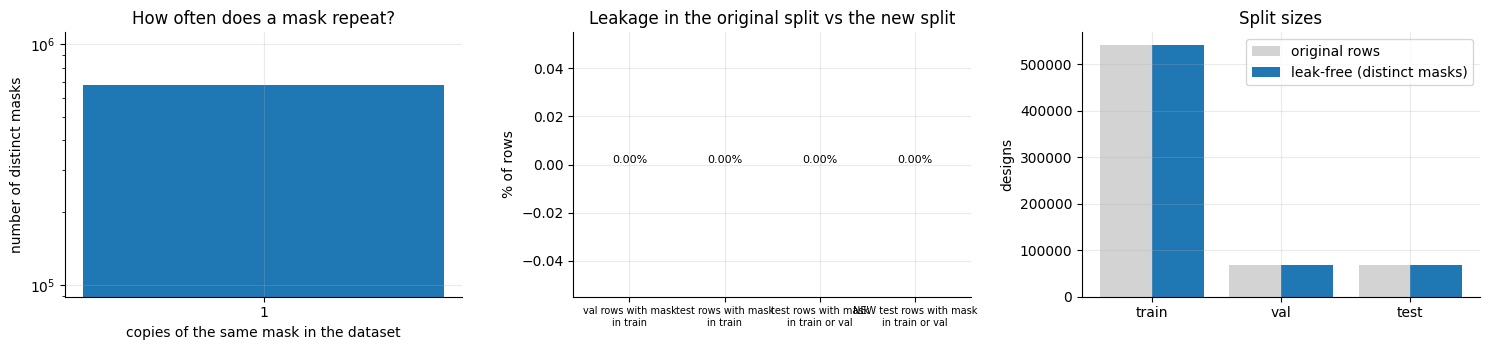

In [35]:
# ---- group id for every distinct mask
def mask_groups(X):
    packed = np.packbits(X > 0.5, axis=1); w = packed.shape[1]; buf = packed.tobytes()
    keys = [buf[i * w:(i + 1) * w] for i in range(len(packed))]
    codes, _ = pd.factorize(pd.Series(keys, dtype=object))
    return codes.astype(np.int64)

gid = mask_groups(X)
n_groups = int(gid.max()) + 1
grp_size = np.bincount(gid)
_, first_row = np.unique(gid, return_index=True)          # first_row[g] = first dataset row that has mask g
U = np.zeros(N, dtype=bool); U[first_row] = True          # U marks ONE representative row per distinct mask
rep = first_row[gid]                                      # for every row: the first row with the same mask

print("Rows: %d | distinct masks: %d | rows that repeat an earlier mask: %d (%.2f%%)" % (N, n_groups, (~U).sum(), 100 * (~U).mean()))
print("Largest group of identical masks:", int(grp_size.max()), "| groups with more than one copy:", int((grp_size > 1).sum()))

# do identical masks have identical spectra? (if not, the dataset has label noise)
dupl_rows = np.where(~U)[0]
if len(dupl_rows):
    d = np.concatenate([np.abs(Y[c] - Y[rep[c]]).max(1) for c in np.array_split(dupl_rows, max(1, len(dupl_rows) // 50000))])
    print("Repeated masks vs their first copy: max |S11 difference| median %.4f dB, 99th pct %.4f dB, max %.3f dB; %.2f%% differ by more than 0.5 dB" % (
        np.median(d), np.percentile(d, 99), d.max(), 100 * (d > 0.5).mean()))

# ---- original split (the one the earlier models were trained with)
idx = np.arange(N)
train0, temp0 = train_test_split(idx, test_size=0.2, random_state=42)
val0, test0 = train_test_split(temp0, test_size=0.5, random_state=42)
g_train0, g_val0 = gid[train0], gid[val0]
leak_val0 = np.isin(g_val0, g_train0)                                       # original val rows whose mask is also in original train
leak_test0_tr = np.isin(gid[test0], g_train0)                               # original test rows whose mask is also in original train
leak_test0 = np.isin(gid[test0], np.concatenate([g_train0, g_val0]))        # ... in original train OR val  (aligned with test0)
print("\nORIGINAL split: train %d | val %d | test %d" % (len(train0), len(val0), len(test0)))
print("  val rows whose mask is in train : %6d (%.2f%%)" % (leak_val0.sum(), 100 * leak_val0.mean()))
print("  test rows whose mask is in train: %6d (%.2f%%)" % (leak_test0_tr.sum(), 100 * leak_test0_tr.mean()))
print("  test rows whose mask is in train or val: %d (%.2f%%)" % (leak_test0.sum(), 100 * leak_test0.mean()))
print("  test rows that are repeats inside the test split: %d" % (len(test0) - len(np.unique(gid[test0]))))

# ---- leak-free splits
def dedup_within(ids):
    _, k = np.unique(gid[ids], return_index=True)
    return np.sort(ids[k])

train_idx = dedup_within(train0)
val_idx = dedup_within(val0[~leak_val0])
test_idx = dedup_within(test0[~leak_test0])
print("\nLEAK-FREE split: train %d | val %d | test %d  (test kept %.1f%% of the original test rows)" % (
    len(train_idx), len(val_idx), len(test_idx), 100 * len(test_idx) / len(test0)))

for nm, a, b in [("train/test", train_idx, test_idx), ("val/test", val_idx, test_idx), ("train/val", train_idx, val_idx)]:
    assert not np.isin(gid[a], gid[b]).any(), f"identical masks shared between {nm}"
for nm, ids in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    assert len(np.unique(gid[ids])) == len(ids), f"repeated masks inside {nm}"
# the earlier models were trained on train0: the new test set must not contain any of its masks
assert not np.isin(gid[test_idx], g_train0).any() and not np.isin(gid[test_idx], g_val0).any()
print("Checks passed: no mask is shared between train / val / test, and the test set contains no mask from the ORIGINAL train or val split.")

# ---- plots: duplicates
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
sizes = np.minimum(grp_size, 10); cs = np.bincount(sizes)[1:]
ax[0].bar(np.arange(1, len(cs) + 1), cs, color="tab:blue"); ax[0].set_yscale("log")
lab_cs = [str(i) for i in range(1, len(cs) + 1)]
if grp_size.max() >= 10: lab_cs[-1] = "10+"
ax[0].set_xticks(np.arange(1, len(cs) + 1)); ax[0].set_xticklabels(lab_cs)
ax[0].set_xlabel("copies of the same mask in the dataset"); ax[0].set_ylabel("number of distinct masks"); ax[0].set_title("How often does a mask repeat?")
labels = ["val rows with mask\nin train", "test rows with mask\nin train", "test rows with mask\nin train or val", "NEW test rows with mask\nin train or val"]
vals = [100 * leak_val0.mean(), 100 * leak_test0_tr.mean(), 100 * leak_test0.mean(), 0.0]
bars = ax[1].bar(range(4), vals, color=["tab:orange", "tab:orange", "tab:red", "tab:green"])
for b_, v in zip(bars, vals): ax[1].text(b_.get_x() + b_.get_width() / 2, v, "%.2f%%" % v, ha="center", va="bottom", fontsize=8)
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(labels, fontsize=7); ax[1].set_ylabel("% of rows"); ax[1].set_title("Leakage in the original split vs the new split")
ax[2].bar(["train", "val", "test"], [len(train0), len(val0), len(test0)], width=0.4, label="original rows", color="lightgray")
ax[2].bar(np.arange(3) + 0.4, [len(train_idx), len(val_idx), len(test_idx)], width=0.4, label="leak-free (distinct masks)", color="tab:blue")
ax[2].set_xticks(np.arange(3) + 0.2); ax[2].set_xticklabels(["train", "val", "test"]); ax[2].set_ylabel("designs"); ax[2].legend(); ax[2].set_title("Split sizes")
save_show("dup_leakage_overview")

## 5. Dataset analysis: which designs resonate, and where?
Definitions used everywhere below (one row per **distinct** mask unless stated):
- **resonant**: S11 <= `THRESH_DB` at some frequency in 10-20 GHz
- **in-band resonant**: S11 <= `THRESH_DB` at some frequency **inside** the band (a deeper dip elsewhere does not matter)
- **resonance frequency** `f_res`: the deepest in-band point if the design is in-band resonant, otherwise the global minimum

Minimum-S11 percentiles (0,5,25,50,75,95,100): [-64.29 -21.42 -12.78  -7.53  -3.97  -2.03  -0.37]
Resonant designs (any S11 <= -10 dB), distinct masks: 249148 of 677479 = 36.8%   (paper: about 180k of 500k = 36%)
   same count including repeated rows: 249148 of 677479 = 36.8%
Number of dips among resonant designs: {1: 216501, 2: 31805, 3: 839, 4: 3}

In-band resonant designs (distinct masks): old rule (global minimum in band) = 138201 | new rule (any dip in band) = 151563 | recovered = 13362 (+9.7%)
Recovered designs by number of dips: {1: 1582, 2: 11403, 3: 375, 4: 2}


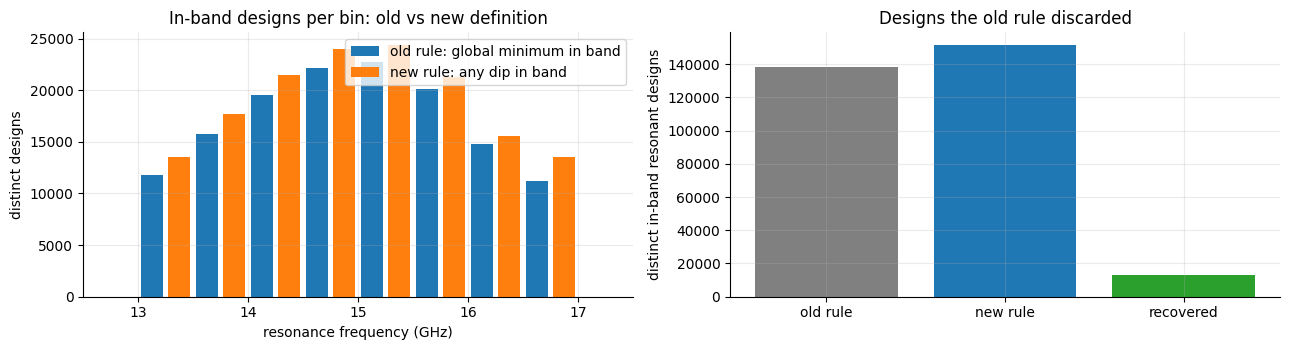

In [36]:
Yb = Y[:, BAND_COLS]
min_s11 = Y.min(1); f_glob = freq[Y.argmin(1)]
res_any = min_s11 <= THRESH                                  # resonant somewhere in 10-20 GHz
res_in = (Yb <= THRESH).any(1)                               # NEW definition: a dip <= THRESH anywhere inside the band
f_band = BAND_FREQ[Yb.argmin(1)]                             # deepest in-band point
f_res = np.where(res_in, f_band, f_glob)                     # resonance frequency used for bins / targets
depth_res = np.where(res_in, Yb.min(1), min_s11)             # depth of that dip
n_bands = n_bands_of(Y)
bw_all = (Y <= THRESH).sum(1) * DF                           # total width below the threshold (GHz), as in your earlier notebook
below_all = Y <= THRESH

print("Minimum-S11 percentiles (0,5,25,50,75,95,100):", np.round(np.percentile(min_s11[U], [0,5,25,50,75,95,100]), 2))
print("Resonant designs (any S11 <= %.0f dB), distinct masks: %d of %d = %.1f%%   (paper: about 180k of 500k = 36%%)" % (
    THRESH, (res_any & U).sum(), U.sum(), 100 * (res_any & U).sum() / U.sum()))
print("   same count including repeated rows: %d of %d = %.1f%%" % (res_any.sum(), N, 100 * res_any.mean()))
print("Number of dips among resonant designs:", dict(zip(*[a.tolist() for a in np.unique(n_bands[res_any & U], return_counts=True)])))

# ---- effect of the corrected in-band definition
old_in = res_any & inband(f_glob)       # OLD: the global minimum lies inside the band
new_in = res_in                         # NEW: a dip <= threshold lies inside the band
assert not (old_in & ~new_in).any()
rec = new_in & ~old_in & U
print("\nIn-band resonant designs (distinct masks): old rule (global minimum in band) = %d | new rule (any dip in band) = %d | recovered = %d (+%.1f%%)" % (
    (old_in & U).sum(), (new_in & U).sum(), rec.sum(), 100 * rec.sum() / max(1, (old_in & U).sum())))
print("Recovered designs by number of dips:", dict(zip(*[a.tolist() for a in np.unique(n_bands[rec], return_counts=True)])))

co = np.bincount(bin_of(f_glob[old_in & U]), minlength=NBINS); cn = np.bincount(bin_of(f_band[new_in & U]), minlength=NBINS)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].bar(edges + BIN_W * 0.25, co, width=BIN_W * 0.4, label="old rule: global minimum in band"); ax[0].bar(edges + BIN_W * 0.75, cn, width=BIN_W * 0.4, label="new rule: any dip in band")
ax[0].set_xlim(LO - 0.5, HI + 0.5); ax[0].set_xlabel("resonance frequency (GHz)"); ax[0].set_ylabel("distinct designs"); ax[0].legend(); ax[0].set_title("In-band designs per bin: old vs new definition")
ax[1].bar(["old rule", "new rule", "recovered"], [(old_in & U).sum(), (new_in & U).sum(), rec.sum()], color=["gray", "tab:blue", "tab:green"])
ax[1].set_ylabel("distinct in-band resonant designs"); ax[1].set_title("Designs the old rule discarded")
save_show("inband_definition_effect")

 bin_start_GHz  bin_end_GHz  resonant_designs  designs_with_dip_in_bin  vs_median  in_band
          10.0         10.5               454                      585       0.03    False
          10.5         11.0               702                      934       0.05    False
          11.0         11.5              1358                     1743       0.10    False
          11.5         12.0              2366                     3144       0.18    False
          12.0         12.5              4273                     5687       0.32    False
          12.5         13.0              7269                     9730       0.55    False
          13.0         13.5             13540                    14690       1.02     True
          13.5         14.0             17696                    19951       1.34     True
          14.0         14.5             21469                    25222       1.62     True
          14.5         15.0             23982                    29840       1.81     True

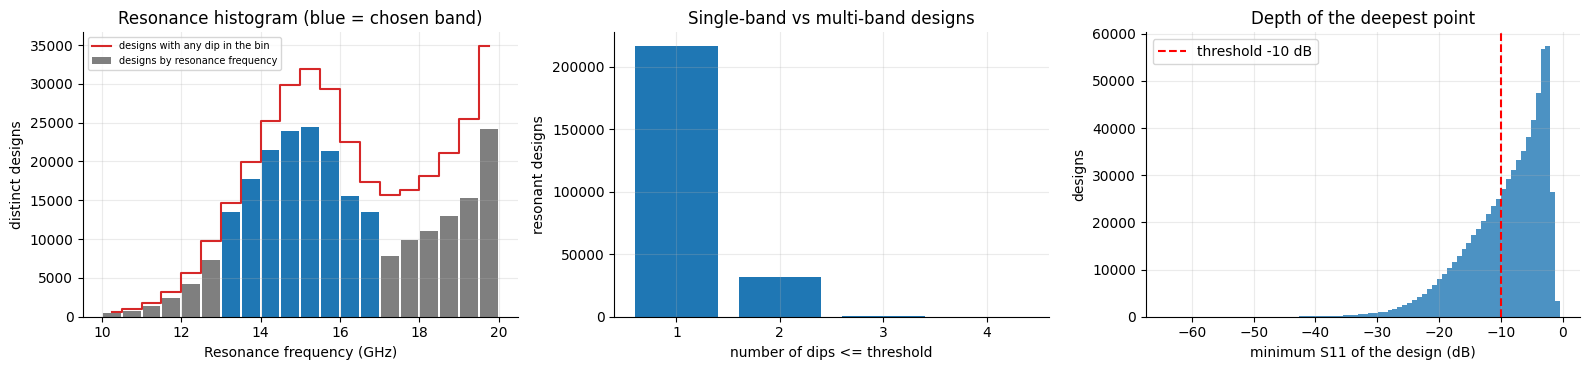

In [37]:
# Histogram of resonance frequency (the idea of the paper's Fig. 3d, on YOUR dataset)
sel_r = res_any & U
cnt = np.bincount(bin_of(f_res[sel_r]), minlength=NBINS)                 # one count per design (at its resonance frequency)
bin_pts = bin_of(freq)
dip_cnt = np.array([(below_all[:, bin_pts == k].any(1) & U).sum() for k in range(NBINS)])   # designs with ANY dip inside the bin
res_hist = pd.DataFrame({"bin_start_GHz": edges, "bin_end_GHz": edges + BIN_W, "resonant_designs": cnt, "designs_with_dip_in_bin": dip_cnt})
med = np.median(cnt[cnt > 0])
res_hist["vs_median"] = (cnt / med).round(2)
res_hist["in_band"] = inband(edges + BIN_W / 2)
print(res_hist.to_string(index=False))
sparse = res_hist[res_hist.vs_median < 0.5]
print("\nSparse bins (< 50% of the median bin):", [f"{a:.1f}-{b:.1f}" for a, b in zip(sparse.bin_start_GHz, sparse.bin_end_GHz)] or "none")
k_hi = cnt.argmax(); k_lo = np.where(cnt > 0, cnt, 10**9).argmin()
print("Densest bin: %.1f-%.1f GHz (%d designs) | sparsest non-empty bin: %.1f-%.1f GHz (%d designs)" % (
    edges[k_hi], edges[k_hi] + BIN_W, cnt[k_hi], edges[k_lo], edges[k_lo] + BIN_W, cnt[k_lo]))
res_hist.to_csv(f"{OUT_DIR}/hist_resonance.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].bar(edges + BIN_W / 2, cnt, width=BIN_W * 0.9, color=np.where(res_hist.in_band, "tab:blue", "tab:gray"), label="designs by resonance frequency")
ax[0].step(edges + BIN_W / 2, dip_cnt, where="mid", color="tab:red", label="designs with any dip in the bin")
ax[0].set_xlabel("Resonance frequency (GHz)"); ax[0].set_ylabel("distinct designs"); ax[0].set_title("Resonance histogram (blue = chosen band)"); ax[0].legend(fontsize=7)
nb_cnt = np.bincount(np.minimum(n_bands[sel_r], 6)); ax[1].bar(np.arange(len(nb_cnt)), nb_cnt)
lab_nb = [str(i) for i in range(1, len(nb_cnt))]
if len(nb_cnt) == 7: lab_nb[-1] = "6+"
ax[1].set_xticks(np.arange(1, len(nb_cnt))); ax[1].set_xticklabels(lab_nb)
ax[1].set_xlim(0.4, len(nb_cnt) - 0.4); ax[1].set_xlabel("number of dips <= threshold"); ax[1].set_ylabel("resonant designs"); ax[1].set_title("Single-band vs multi-band designs")
ax[2].hist(min_s11[U], bins=80, color="tab:blue", alpha=0.8); ax[2].axvline(THRESH, color="r", ls="--", label="threshold %.0f dB" % THRESH)
ax[2].set_xlabel("minimum S11 of the design (dB)"); ax[2].set_ylabel("designs"); ax[2].set_title("Depth of the deepest point"); ax[2].legend()
save_show("hist_resonance")

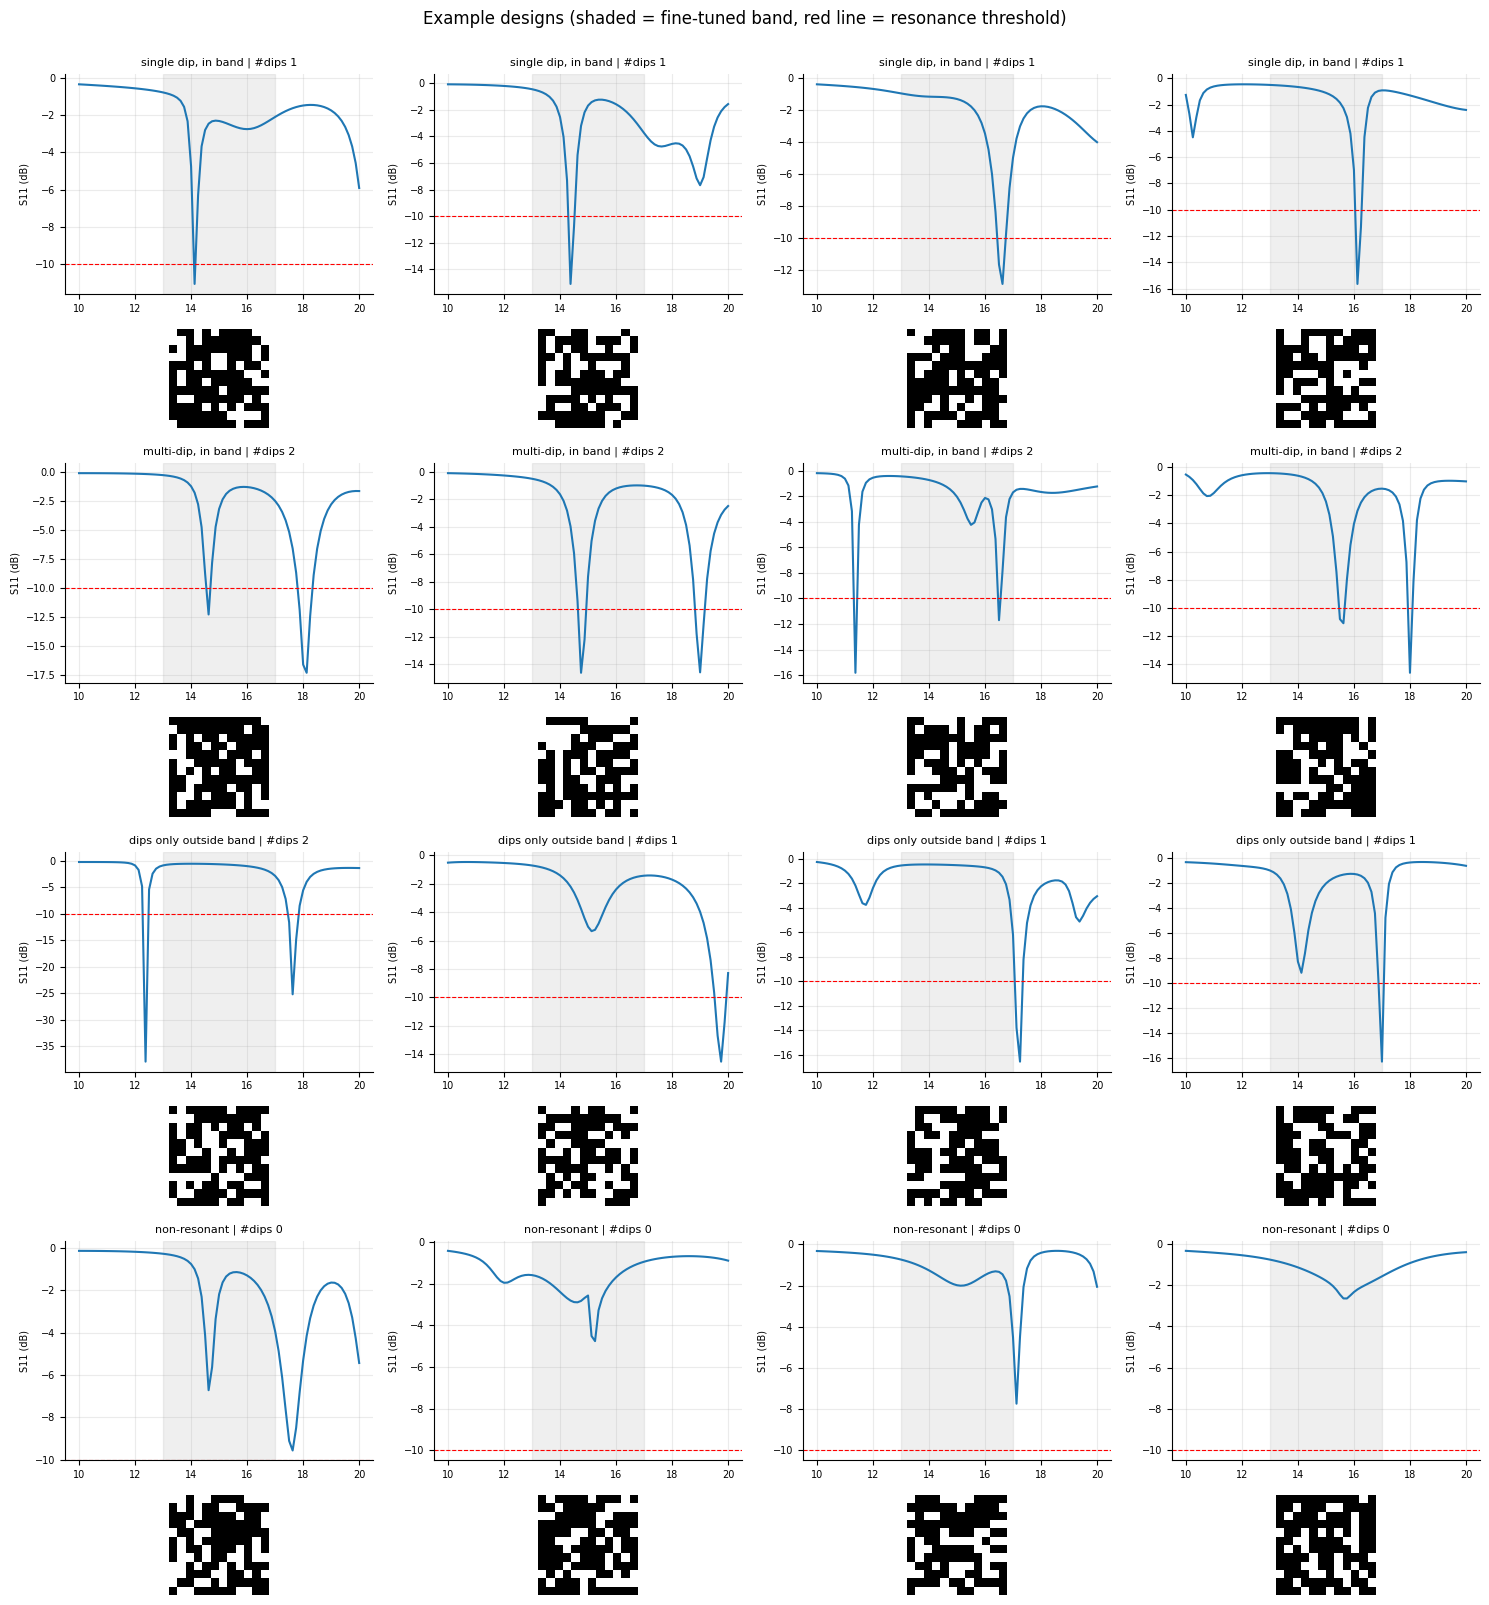

In [38]:
# Example designs: spectra with their masks (single-dip in band, multi-dip in band, dip only outside band, non-resonant)
rng_ex = np.random.default_rng(0)
groups_ex = [("single dip, in band", res_in & (n_bands == 1)), ("multi-dip, in band", res_in & (n_bands >= 2)),
             ("dips only outside band", res_any & ~res_in), ("non-resonant", ~res_any)]
nc = 4
fig = plt.figure(figsize=(15, 4.0 * len(groups_ex)))
gs = fig.add_gridspec(2 * len(groups_ex), nc, height_ratios=[2.2, 1.0] * len(groups_ex))
for r, (title, cond) in enumerate(groups_ex):
    pool_ex = np.where(cond & U)[0]
    pick = rng_ex.choice(pool_ex, min(nc, len(pool_ex)), replace=False) if len(pool_ex) else []
    for c, i in enumerate(pick):
        a1 = fig.add_subplot(gs[2 * r, c]); a2 = fig.add_subplot(gs[2 * r + 1, c])
        a1.plot(freq, Y[i], color="tab:blue"); a1.axhline(THRESH, color="r", ls="--", lw=0.8); a1.axvspan(LO, HI, color="gray", alpha=0.12)
        a1.set_title("%s | #dips %d" % (title, n_bands[i]), fontsize=8); a1.set_ylabel("S11 (dB)", fontsize=7); a1.tick_params(labelsize=7)
        a2.imshow(X[i].reshape(12, 12), cmap="Greys", vmin=0, vmax=1); a2.axis("off")
plt.suptitle("Example designs (shaded = fine-tuned band, red line = resonance threshold)", y=1.0)
save_show("dataset_examples")

 bin_start_GHz     n  median_depth_dB  median_bw_GHz  mean_pixels_on  single_dip_%
          10.0   454           -13.23           0.12       93.330002         88.99
          10.5   702           -12.82           0.12       93.489998         92.17
          11.0  1358           -12.97           0.12       93.430000         91.46
          11.5  2366           -12.99           0.12       93.820000         89.43
          12.0  4273           -13.02           0.12       94.419998         90.05
          12.5  7269           -13.31           0.12       94.639999         89.74
          13.0 13540           -13.55           0.12       95.239998         75.01
          13.5 17696           -14.08           0.25       95.690002         76.68
          14.0 21469           -14.74           0.25       95.910004         79.82
          14.5 23982           -14.89           0.25       96.160004         82.54
          15.0 24392           -15.04           0.25       96.650002         84.33
    

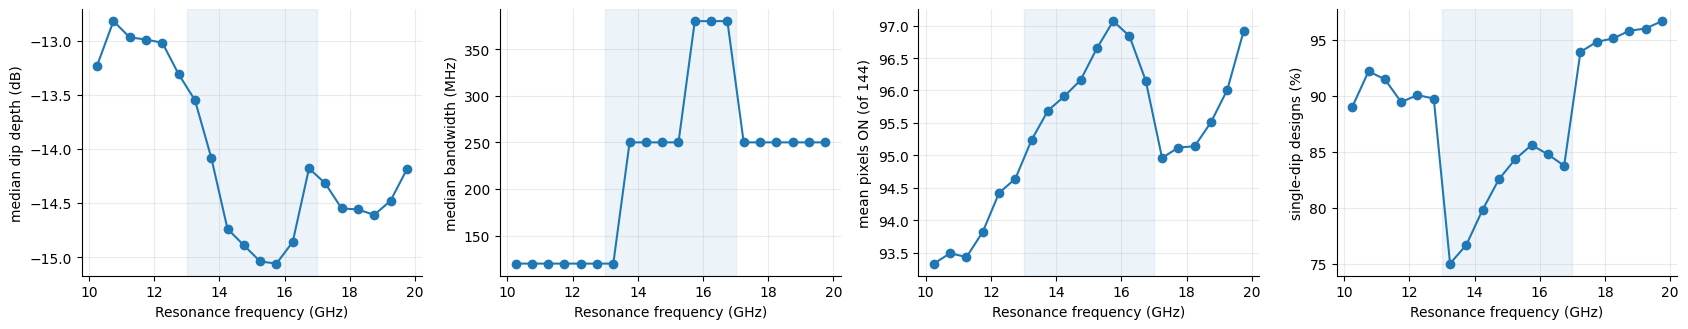

In [39]:
# Per-bin characteristics of the resonant designs: dip depth, number of dips, bandwidth, amount of metal
rd = pd.DataFrame({"bin": bin_of(f_res[sel_r]), "depth": depth_res[sel_r], "bw": bw_all[sel_r],
                   "single": (n_bands[sel_r] == 1).astype(float), "pixels_on": X[sel_r].sum(1)})
bin_stats = rd.groupby("bin").agg(n=("depth", "size"), median_depth_dB=("depth", "median"), single=("single", "mean"),
                                  median_bw_GHz=("bw", "median"), mean_pixels_on=("pixels_on", "mean")).reset_index()
bin_stats.insert(0, "bin_start_GHz", edges[bin_stats["bin"].values]); bin_stats["single_dip_%"] = 100 * bin_stats["single"]
bin_stats = bin_stats.drop(columns=["bin", "single"]).round(2)
print(bin_stats.to_string(index=False)); bin_stats.to_csv(f"{OUT_DIR}/bin_stats.csv", index=False)

fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
x = bin_stats.bin_start_GHz + BIN_W / 2
ax[0].plot(x, bin_stats.median_depth_dB, "o-"); ax[0].set_ylabel("median dip depth (dB)")
ax[1].plot(x, bin_stats.median_bw_GHz * 1000, "o-"); ax[1].set_ylabel("median bandwidth (MHz)")
ax[2].plot(x, bin_stats.mean_pixels_on, "o-"); ax[2].set_ylabel("mean pixels ON (of 144)")
ax[3].plot(x, bin_stats["single_dip_%"], "o-"); ax[3].set_ylabel("single-dip designs (%)")
for a in ax: a.set_xlabel("Resonance frequency (GHz)"); a.axvspan(LO, HI, color="tab:blue", alpha=0.08)
save_show("bin_stats")

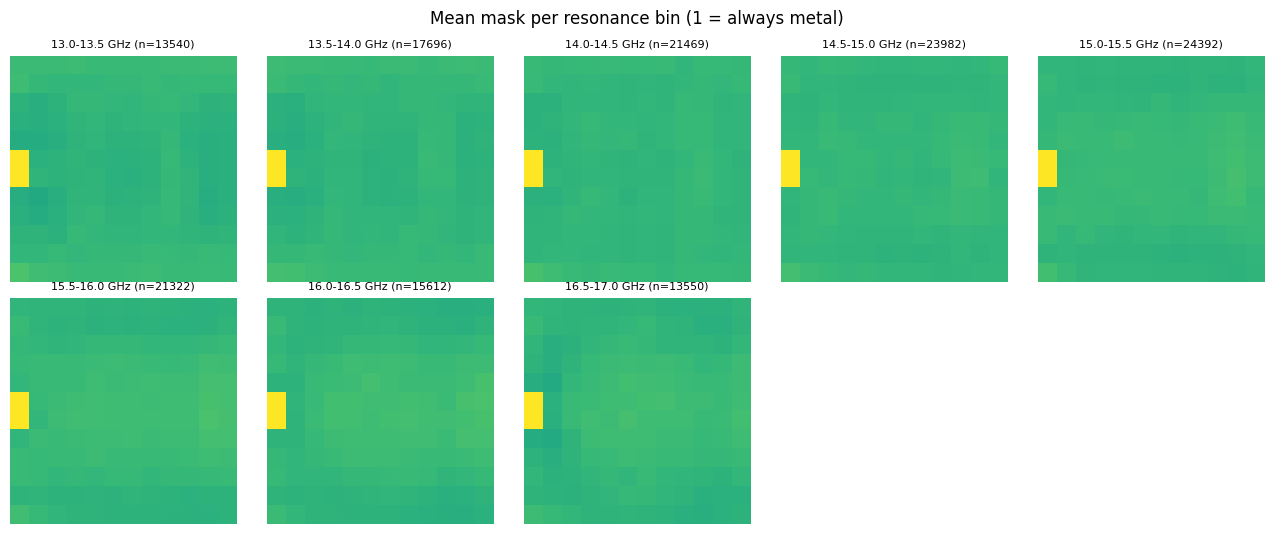

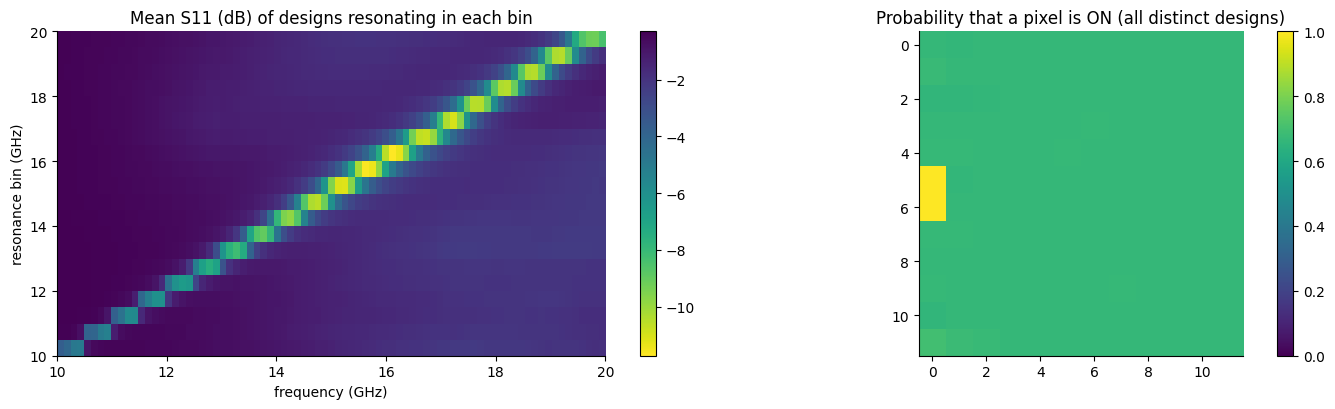

In [40]:
# Mean mask and mean S11 spectrum of the resonant designs in each resonance bin
rb = bin_of(f_res)
band_bins = [k for k in range(NBINS) if inband(edges[k] + BIN_W / 2)]
ncol = 5; nrow = int(np.ceil(len(band_bins) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(2.6 * ncol, 2.7 * nrow))
for ax, k in zip(np.atleast_1d(axs).ravel(), band_bins):
    sel = sel_r & (rb == k)
    ax.imshow(X[sel].mean(0).reshape(12, 12), cmap="viridis", vmin=0, vmax=1)
    ax.set_title("%.1f-%.1f GHz (n=%d)" % (edges[k], edges[k] + BIN_W, sel.sum()), fontsize=8); ax.axis("off")
for ax in np.atleast_1d(axs).ravel()[len(band_bins):]: ax.axis("off")
plt.suptitle("Mean mask per resonance bin (1 = always metal)")
save_show("mean_masks")

mean_spec = np.full((NBINS, 81), np.nan)
for k in range(NBINS):
    sel = sel_r & (rb == k)
    if sel.any(): mean_spec[k] = Y[sel].mean(0)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
im = ax[0].imshow(mean_spec, aspect="auto", origin="lower", extent=[10, 20, 10, 20], cmap="viridis_r")
ax[0].set_xlabel("frequency (GHz)"); ax[0].set_ylabel("resonance bin (GHz)"); ax[0].set_title("Mean S11 (dB) of designs resonating in each bin"); plt.colorbar(im, ax=ax[0])
ax[0].grid(False)
mp = X[U].mean(0).reshape(12, 12); im2 = ax[1].imshow(mp, cmap="viridis", vmin=0, vmax=1); ax[1].set_title("Probability that a pixel is ON (all distinct designs)")
ax[1].grid(False); plt.colorbar(im2, ax=ax[1])
save_show("mean_spectra_and_pixel_map")

## 6. Baseline analysis: does the current model fail where the data is sparse?
Each resonant test design's own spectrum is the target: spectrum -> inverse model -> binary mask -> frozen forward model.

The **target dip** of a test design is its deepest in-band point if it has an in-band dip, otherwise its global minimum. **Success** = the predicted spectrum has a dip <= `THRESH_DB` within `TOL_GHZ` of the target dip. (`legacy_success_%` = the old rule: the predicted *global minimum* is within `TOL_GHZ` of the target's global minimum.)

Resonant test designs: 24891 (in band: 15200, outside band: 9691)
Previous fine-tuned model: success 46.9% overall | in band 68.5% | outside band 13.1%
Spearman correlation between bin density and success rate: rho = 0.70 (p = 0.001)

Failure types (previous model, all resonant test designs):
success_%                   46.9
dip_elsewhere_%              1.7
right_freq_but_shallow_%    28.3
wrong_freq_and_shallow_%    23.1

Soft vs binary mask: mean spectrum difference 0.006 dB | pixels that are not near 0/1: 0.14%

Per-bin results of the previous model:
 bin_start_GHz    n  success_%  median_res_err_GHz  median_bw_err_GHz
          10.0   42       0.00                6.69               0.12
          10.5   72       0.00                5.94               0.12
          11.0  139       0.00                5.62               0.12
          11.5  227       0.00                5.25               0.12
          12.0  417       0.00                4.38               0.12
          12.5  703 

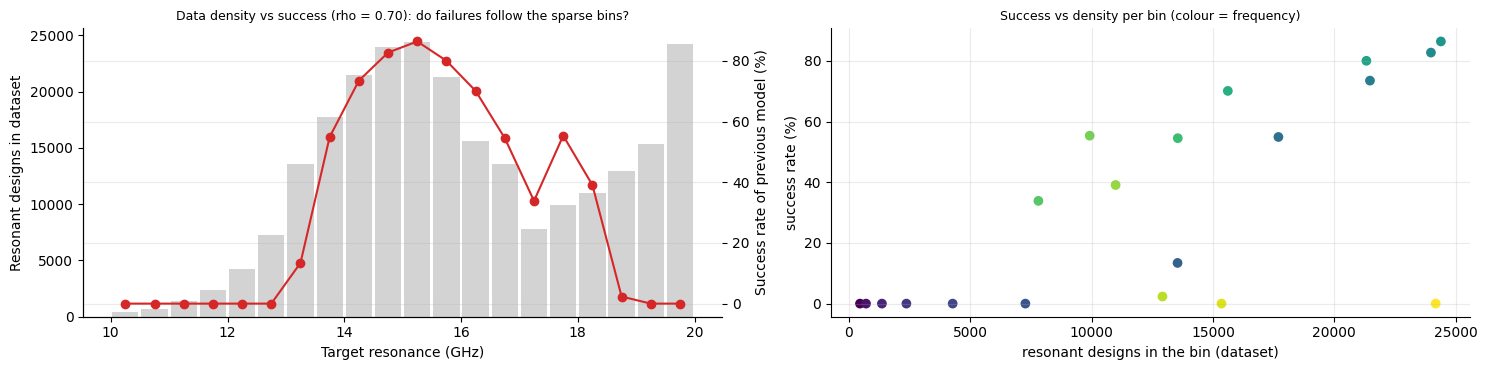

In [41]:
@torch.inference_mode()
def predict_spectra(model, S, bs=1024):
    model.eval(); P, M = [], []
    for i in range(0, len(S), bs):
        s = torch.from_numpy(np.ascontiguousarray(S[i:i+bs])).to(device)
        m = (model(s) >= 0.5).float()                          # binary mask, as in your evaluation
        P.append(fwd(m.reshape(-1, 1, 12, 12)).cpu().numpy()); M.append(m.cpu().numpy())
    return np.concatenate(P), np.concatenate(M)

@torch.inference_mode()
def soft_binary_gap(model, ids, bs=1024):
    model.eval(); gaps, mid = [], []
    for i in range(0, len(ids), bs):
        s = torch.from_numpy(np.ascontiguousarray(Y[ids[i:i+bs]])).to(device)
        soft = model(s); binm = (soft >= 0.5).float()
        ps = fwd(soft.reshape(-1, 1, 12, 12)); pb = fwd(binm.reshape(-1, 1, 12, 12))
        gaps.append((ps - pb).abs().mean(1).cpu().numpy()); mid.append(((soft > 0.05) & (soft < 0.95)).float().mean(1).cpu().numpy())
    return float(np.concatenate(gaps).mean()), float(100 * np.concatenate(mid).mean())

def target_dip(S):
    # deepest in-band point if the target has a dip <= THRESH inside the band, otherwise its global minimum
    Sb = S[:, BAND_COLS]; inb = (Sb <= THRESH).any(1)
    f_t = np.where(inb, BAND_FREQ[Sb.argmin(1)], freq[S.argmin(1)])
    m_t = np.where(inb, Sb.min(1), S.min(1))
    return f_t, m_t, inb

def score(S_tgt, S_pred):
    tol = CFG["TOL_GHZ"] + 1e-9
    t_f, t_min, t_in = target_dip(S_tgt)
    p_min = S_pred.min(1); p_fg = freq[S_pred.argmin(1)]
    below = S_pred <= THRESH; any_dip = below.any(1)
    dist = np.abs(freq[None, :] - t_f[:, None])
    win_min = np.where(dist <= tol, S_pred, np.inf).min(1)             # deepest predicted point within +-TOL of the target dip
    hit = win_min <= THRESH                                            # a dip <= THRESH exists at the target frequency
    dd = np.where(below, dist, np.inf)
    pred_f = np.where(any_dip, freq[dd.argmin(1)], p_fg)               # the predicted dip nearest to the target (or the global minimum if none)
    res_err = np.where(any_dip, dd.min(1), np.abs(p_fg - t_f))
    near_glob = np.abs(p_fg - t_f) <= tol
    t_bw = (S_tgt <= THRESH).sum(1) * DF; p_bw = below.sum(1) * DF
    legacy = (np.abs(p_fg - freq[S_tgt.argmin(1)]) <= tol) & any_dip   # the OLD success rule
    return pd.DataFrame({
        "tgt_f": t_f, "tgt_min": t_min, "tgt_in_band": t_in, "pred_f": pred_f, "pred_min": p_min, "pred_win_min": win_min,
        "spec_mae": np.abs(S_pred - S_tgt).mean(1), "res_err": res_err, "min_err": np.abs(win_min - t_min),
        "tgt_bw": t_bw, "pred_bw": p_bw, "bw_err": np.abs(p_bw - t_bw),
        "success": hit, "success_legacy": legacy,
        "f_elsewhere": ~hit & any_dip, "f_shallow_right": ~any_dip & near_glob, "f_shallow_wrong": ~any_dip & ~near_glob})

PRED = {}                                                   # cache: model name -> (predicted spectra, binary masks) on test_res
def evaluate(model, ids, key=None):
    P, M = predict_spectra(model, Y[ids])
    if key is not None: PRED[key] = (P, M)
    return score(Y[ids], P)

def summarize(df):
    return pd.Series({"n": len(df), "success_%": 100 * df.success.mean(), "legacy_success_%": 100 * df.success_legacy.mean(),
                      "median_res_err_GHz": df.res_err.median(), "mean_res_err_GHz": df.res_err.mean(), "spec_MAE_dB": df.spec_mae.mean(),
                      "dip_depth_err_dB": df.min_err.mean(), "bw_err_GHz": df.bw_err.mean()})

def failure_types(df):
    return pd.Series({"success_%": 100 * df.success.mean(), "dip_elsewhere_%": 100 * df.f_elsewhere.mean(),
                      "right_freq_but_shallow_%": 100 * df.f_shallow_right.mean(), "wrong_freq_and_shallow_%": 100 * df.f_shallow_wrong.mean()})

def per_bin_table(df):
    g = df.assign(bin=bin_of(df.tgt_f.values)).groupby("bin")
    t = pd.DataFrame({"n": g.size(), "success_%": 100 * g.success.mean(), "median_res_err_GHz": g.res_err.median(),
                      "median_bw_err_GHz": g.bw_err.median()}).reindex(range(NBINS))
    t["n"] = t["n"].fillna(0).astype(int)
    t.insert(0, "bin_start_GHz", edges); return t

test_res = test_idx[res_any[test_idx]]                       # resonant test designs (leak-free test set)
is_in = res_in[test_res]                                     # True: has a dip <= THRESH inside the band
print("Resonant test designs: %d (in band: %d, outside band: %d)" % (len(test_res), is_in.sum(), (~is_in).sum()))

base_df = evaluate(prev_model, test_res, key="Previous fine-tuned")
base_tab = per_bin_table(base_df)
ok = (base_tab["n"] > 0).values & (cnt > 0)
rho, pval = spearmanr(cnt[ok], base_tab["success_%"].values[ok])
print("Previous fine-tuned model: success %.1f%% overall | in band %.1f%% | outside band %.1f%%" % (
    100 * base_df.success.mean(), 100 * base_df.success[is_in].mean(), 100 * base_df.success[~is_in].mean()))
print("Spearman correlation between bin density and success rate: rho = %.2f (p = %.3f)" % (rho, pval))
print("\nFailure types (previous model, all resonant test designs):"); print(failure_types(base_df).round(1).to_string())
gap, midpct = soft_binary_gap(prev_model, test_res[:5000])
print("\nSoft vs binary mask: mean spectrum difference %.3f dB | pixels that are not near 0/1: %.2f%%" % (gap, midpct))
print("\nPer-bin results of the previous model:"); print(base_tab.round(2).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(15, 3.8)); ax2 = ax[0].twinx()
ax[0].bar(edges + BIN_W / 2, cnt, width=BIN_W * 0.9, color="lightgray"); ax[0].set_ylabel("Resonant designs in dataset"); ax[0].grid(False)
ax2.plot(edges + BIN_W / 2, base_tab["success_%"].values, "o-", color="tab:red"); ax2.set_ylabel("Success rate of previous model (%)")
ax[0].set_xlabel("Target resonance (GHz)"); ax[0].set_title("Data density vs success (rho = %.2f): do failures follow the sparse bins?" % rho, fontsize=9)
ax[1].scatter(cnt[ok], base_tab["success_%"].values[ok], c=(edges[ok] + BIN_W / 2), cmap="viridis")
ax[1].set_xlabel("resonant designs in the bin (dataset)"); ax[1].set_ylabel("success rate (%)"); ax[1].set_title("Success vs density per bin (colour = frequency)", fontsize=9)
save_show("density_vs_success_prev")

## 7. Build the balanced in-band subset
- keep designs that have a dip <= threshold **anywhere inside the band** (not just their global minimum); each design is binned by its deepest in-band dip
- equal number per bin: bins with many designs are sub-sampled; sparse bins are repeated (at most `MAX_REPEAT` times)
- the validation set is balanced the same way, but only by sub-sampling
- both pools contain **distinct masks only** and share no mask with each other or with the test set

In [42]:
def balanced_subset(pool, rng, cap, repeat, cfg):
    ok = res_in[pool]
    if cfg["SINGLE_BAND_ONLY"]: ok &= (n_bands[pool] == 1)
    sel = pool[ok]; b = bin_of(f_res[sel])
    counts = np.bincount(b, minlength=NBINS)
    used_bins = [k for k in range(NBINS) if counts[k] > 0]
    target = int(min(cap, np.median(counts[used_bins])))
    out = []
    for k in used_bins:
        ids = sel[b == k]
        if len(ids) >= target:
            out.append(rng.choice(ids, target, replace=False))
        else:
            out.append(np.tile(ids, int(min(repeat, max(1, target // len(ids))))))
    return np.concatenate(out), counts, target

def build_sets(cfg):
    rng = np.random.default_rng(cfg["SEED"])
    tr, tr_av, tr_t = balanced_subset(train_idx, rng, cfg["MAX_PER_BIN"], cfg["MAX_REPEAT"], cfg)
    va, va_av, va_t = balanced_subset(val_idx, rng, cfg["VAL_CAP"], 1, cfg)
    n_main = len(tr)
    if cfg["REPLAY_FRAC"] > 0:
        tr = np.concatenate([tr, rng.choice(train_idx, int(cfg["REPLAY_FRAC"] * len(tr)), replace=False)])
    t = lambda a, ids: torch.from_numpy(np.ascontiguousarray(a[ids])).to(device)
    # spectra (St) and design targets (Mt) are both taken with the SAME index array, so row i of both belongs to the same design
    return dict(tr_ids=tr, va_ids=va, n_main=n_main, tr_avail=tr_av, tr_target=tr_t, va_target=va_t,
                St=t(Y, tr), Mt=t(X, tr), Sv=t(Y, va), Mv=t(X, va))

SETS = build_sets(CFG)
tr_ids, va_ids, n_main = SETS["tr_ids"], SETS["va_ids"], SETS["n_main"]
assert res_in[tr_ids[:n_main]].all() and res_in[va_ids].all(), "a subset design has no dip <= threshold inside the band"
used_tr = np.bincount(bin_of(f_res[tr_ids[:n_main]]), minlength=NBINS)
sub_df = pd.DataFrame({"bin_start_GHz": edges, "available_in_train": SETS["tr_avail"], "used_in_train_subset": used_tr})
print(sub_df[sub_df.available_in_train > 0].to_string(index=False))
print("\nTrain subset: %d designs (target per bin %d) | validation subset: %d designs (target per bin %d)" %
      (len(tr_ids), SETS["tr_target"], len(va_ids), SETS["va_target"]))
print("Share of the leak-free training pool: %.2f%%" % (100 * len(tr_ids) / len(train_idx)))
sub_df.to_csv(f"{OUT_DIR}/subset_bin_counts.csv", index=False)

 bin_start_GHz  available_in_train  used_in_train_subset
          13.0               10855                  6000
          13.5               14224                  6000
          14.0               17233                  6000
          14.5               19210                  6000
          15.0               19573                  6000
          15.5               16989                  6000
          16.0               12514                  6000
          16.5               10803                  6000

Train subset: 48000 designs (target per bin 6000) | validation subset: 4000 designs (target per bin 500)
Share of the leak-free training pool: 8.86%


                               natural in-band resonant (train)  balanced training subset
designs                                               121401.00                  48000.00
median in-band dip depth (dB)                            -14.59                    -14.48
single-dip %                                              81.88                     81.52
mean pixels ON                                            96.25                     96.20
median total bandwidth (GHz)                               0.25                      0.25

Distinct designs in the subset: 48000 of 48000 rows (1.00x average repetition, from up-sampling sparse bins)
Leakage by mask: training subset / validation subset / test set share NO identical mask (OK)
(for reference) In the ORIGINAL test split, 0.00% of all rows had a mask that was also in the original training split
training subset    forward(true mask) vs true spectrum: MAE 0.435 dB | with shuffled masks: 1.782 dB  -> aligned (OK)
validation subset  fo

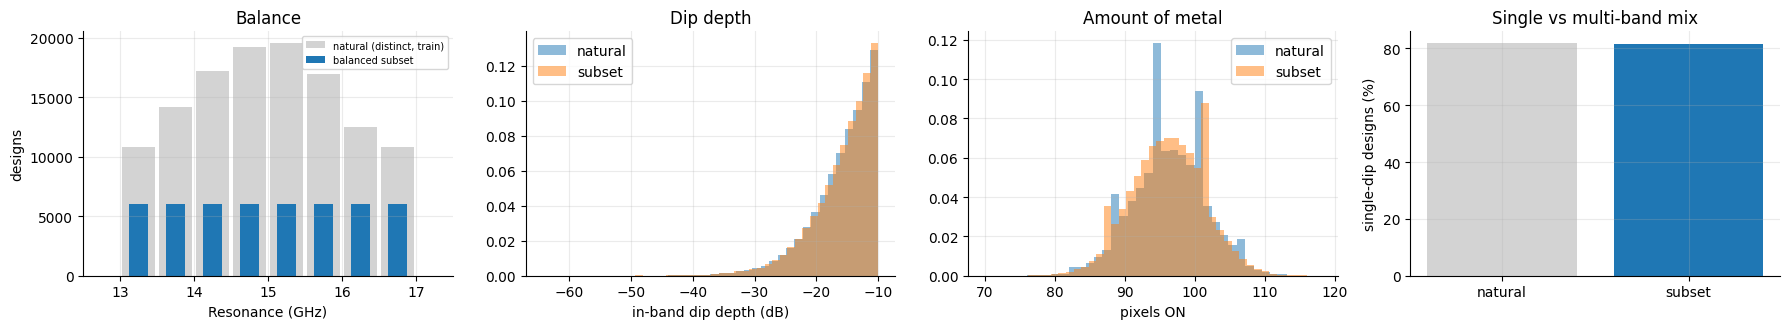

In [43]:
# Subset analysis: balance, similarity to the natural in-band distribution, duplicates and leakage
natural = train_idx[res_in[train_idx]]
main_ids = tr_ids[:n_main]
cmp = pd.DataFrame({
    "natural in-band resonant (train)": [len(natural), np.median(depth_res[natural]), 100 * (n_bands[natural] == 1).mean(), X[natural].sum(1).mean(), np.median(bw_all[natural])],
    "balanced training subset":         [len(main_ids), np.median(depth_res[main_ids]), 100 * (n_bands[main_ids] == 1).mean(), X[main_ids].sum(1).mean(), np.median(bw_all[main_ids])],
}, index=["designs", "median in-band dip depth (dB)", "single-dip %", "mean pixels ON", "median total bandwidth (GHz)"]).round(2)
print(cmp.to_string())
print("\nDistinct designs in the subset: %d of %d rows (%.2fx average repetition, from up-sampling sparse bins)" % (
    len(np.unique(tr_ids)), len(tr_ids), len(tr_ids) / len(np.unique(tr_ids))))

# ---- leakage checks (by MASK, not just by row index)
assert len(np.intersect1d(tr_ids, test_idx)) == 0 and len(np.intersect1d(va_ids, test_idx)) == 0, "subset overlaps with the test set (index)"
assert not np.isin(gid[tr_ids], gid[test_idx]).any(), "a training-subset mask also occurs in the test set"
assert not np.isin(gid[va_ids], gid[test_idx]).any(), "a validation-subset mask also occurs in the test set"
assert not np.isin(gid[va_ids], gid[tr_ids]).any(), "a validation-subset mask also occurs in the training subset"
print("Leakage by mask: training subset / validation subset / test set share NO identical mask (OK)")
print("(for reference) In the ORIGINAL test split, %.2f%% of all rows had a mask that was also in the original training split" % (100 * leak_test0_tr.mean()))

# ---- do the design targets (Mt) belong to the spectra (St)?  Forward model on the TRUE mask must reproduce the TRUE spectrum
@torch.inference_mode()
def pair_check(ids, n=4000):
    ids = np.random.default_rng(0).choice(ids, min(n, len(ids)), replace=False)
    s = torch.from_numpy(Y[ids]).to(device); m = torch.from_numpy(X[ids]).to(device)
    aligned = (fwd(m.reshape(-1, 1, 12, 12)) - s).abs().mean().item()
    perm = torch.randperm(len(ids), generator=torch.Generator().manual_seed(0)).to(device)
    shuffled = (fwd(m[perm].reshape(-1, 1, 12, 12)) - s).abs().mean().item()
    return aligned, shuffled

assert np.array_equal(SETS["Mt"][:64].cpu().numpy(), X[tr_ids[:64]]) and np.array_equal(SETS["St"][:64].cpu().numpy(), Y[tr_ids[:64]])
for nm, ids in [("training subset", tr_ids[:n_main]), ("validation subset", va_ids)]:
    a_, s_ = pair_check(ids)
    print("%-18s forward(true mask) vs true spectrum: MAE %.3f dB | with shuffled masks: %.3f dB  -> %s" % (
        nm, a_, s_, "aligned (OK)" if a_ < 0.5 * s_ else "WARNING: masks and spectra do not look aligned, check mask orientation/encoding"))

fig, ax = plt.subplots(1, 4, figsize=(18, 3.4))
b_nat = np.bincount(bin_of(f_res[natural]), minlength=NBINS)
ax[0].bar(edges + BIN_W / 2, b_nat, width=BIN_W * 0.9, color="lightgray", label="natural (distinct, train)"); ax[0].bar(edges + BIN_W / 2, used_tr, width=BIN_W * 0.5, label="balanced subset")
ax[0].set_xlim(LO - 0.5, HI + 0.5); ax[0].set_xlabel("Resonance (GHz)"); ax[0].set_ylabel("designs"); ax[0].legend(fontsize=7); ax[0].set_title("Balance")
ax[1].hist(depth_res[natural], bins=40, alpha=0.5, density=True, label="natural"); ax[1].hist(depth_res[main_ids], bins=40, alpha=0.5, density=True, label="subset")
ax[1].set_xlabel("in-band dip depth (dB)"); ax[1].legend(); ax[1].set_title("Dip depth")
ax[2].hist(X[natural].sum(1), bins=40, alpha=0.5, density=True, label="natural"); ax[2].hist(X[main_ids].sum(1), bins=40, alpha=0.5, density=True, label="subset")
ax[2].set_xlabel("pixels ON"); ax[2].legend(); ax[2].set_title("Amount of metal")
ax[3].bar(["natural", "subset"], [100 * (n_bands[natural] == 1).mean(), 100 * (n_bands[main_ids] == 1).mean()], color=["lightgray", "tab:blue"])
ax[3].set_ylabel("single-dip designs (%)"); ax[3].set_title("Single vs multi-band mix")
save_show("subset_analysis")

## 8. Fine-tune with a decaying learning rate
Starts from your previous fine-tuned inverse model with a fresh Adam optimizer. The forward model is frozen.

`loss = L_spec + ALPHA * L_design + BETA * L_binary`

- `L_spec`: MSE between the forward-model spectrum of the **soft** mask and the target spectrum (dB squared)
- `L_design`: MSE between the soft mask and the dataset mask of the same design (a regulariser: several different masks can give the same spectrum)
- `L_binary`: pushes pixels to 0/1
- every epoch the four terms are logged **separately**, together with the **hard-mask spectrum MAE in dB** (binary mask through the forward model = what you actually get when you build the antenna)

The best checkpoint is chosen on the in-band validation set by `SELECT_BY`.

In [66]:
mse = nn.MSELoss()
SEL_IDX = {"total": 0, "spec": 1, "spec_bin_mae": 4}

def finetune(cfg, sets, save_path=None, verbose=True):
    torch.manual_seed(cfg["SEED"])
    model, _ = load_inverse(INV_PATH); model.train()
    opt = torch.optim.Adam(model.parameters(), lr=cfg["LR"])
    if cfg["SCHEDULER"] == "cosine":
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["EPOCHS"], eta_min=cfg["LR_MIN"])
    elif cfg["SCHEDULER"] == "plateau":
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2, min_lr=cfg["LR_MIN"])
    else:
        sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, cfg["EPOCHS"] // 5), gamma=0.5)
    sel = SEL_IDX[cfg["SELECT_BY"]]

    def tandem_loss(out, S, M):
        ls = mse(fwd(out.reshape(-1, 1, 12, 12)), S)          # spectrum loss
        ld = mse(out, M)                                      # design loss (M = mask of the same design)
        lb = ((out * (out - 1.0)) ** 2).mean()               # binary loss
        return ls + cfg["ALPHA"] * ld + cfg["BETA"] * lb, ls, ld, lb

    def batches(S, M, bs, shuffle):
        n = len(S); order = torch.randperm(n, device=S.device) if shuffle else torch.arange(n, device=S.device)
        for i in range(0, n, bs):
            j = order[i:i + bs]
            if shuffle and len(j) < 2: break               # BatchNorm needs more than one sample
            yield S[j], M[j]

    def run_epoch(S, M, train):
        model.train(train)
        if train:
            for mod in model.modules():
                if isinstance(mod, nn.BatchNorm1d): mod.eval()   # keep BN running stats frozen
        tot = np.zeros(5); n = 0          # [total, spec, design, binary, hard-mask spectrum MAE]
        with torch.set_grad_enabled(train):
            for s, m_true in batches(S, M, cfg["BATCH"], shuffle=train):
                out = model(s)
                loss, ls, ld, lb = tandem_loss(out, s, m_true)
                if train:
                    opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
                bm = 0.0
                if not train:
                    bm = (fwd((out.detach() >= 0.5).float().reshape(-1, 1, 12, 12)) - s).abs().mean().item()
                k = len(s); tot += k * np.array([loss.item(), ls.item(), ld.item(), lb.item(), bm]); n += k
        r = tot / n
        if train: r[4] = np.nan
        return r

    v0 = run_epoch(sets["Sv"], sets["Mv"], False)
    if verbose: print("Starting model: in-band validation loss %.5f (spectrum %.4f, design %.5f, binary %.5f) | hard-mask spectrum MAE %.3f dB" % (v0[0], v0[1], v0[2], v0[3], v0[4]))
    nan = np.nan
    hist = [dict(epoch=0, lr=cfg["LR"], train_loss=nan, train_spec=nan, train_design=nan, train_binary=nan,
                 val_loss=v0[0], val_spec=v0[1], val_design=v0[2], val_binary=v0[3], val_spec_bin_mae=v0[4])]
    best, bad, best_epoch = v0[sel], 0, 0
    best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}; improved = False
    for epoch in range(1, cfg["EPOCHS"] + 1):
        lr_now = opt.param_groups[0]["lr"]
        tr = run_epoch(sets["St"], sets["Mt"], True); va = run_epoch(sets["Sv"], sets["Mv"], False)
        if cfg["SCHEDULER"] == "plateau": sched.step(va[sel])
        else: sched.step()
        hist.append(dict(epoch=epoch, lr=lr_now, train_loss=tr[0], train_spec=tr[1], train_design=tr[2], train_binary=tr[3],
                         val_loss=va[0], val_spec=va[1], val_design=va[2], val_binary=va[3], val_spec_bin_mae=va[4]))
        flag = ""
        if va[sel] < best - 1e-6:
            best, bad, flag, improved, best_epoch = va[sel], 0, "  <- best", True, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            if save_path: torch.save({"epoch": epoch, "state_dict": best_state, "val_loss": va[0], "select_by": cfg["SELECT_BY"], "config": cfg}, save_path)
        else:
            bad += 1
        if verbose: print("Epoch %2d/%d | lr %.2e | train %.5f | val %.5f (spec %.4f, design %.5f, binary %.5f) | hard-mask MAE %.3f dB%s" %
                          (epoch, cfg["EPOCHS"], lr_now, tr[0], va[0], va[1], va[2], va[3], va[4], flag))
        if bad >= cfg["PATIENCE"]:
            if verbose: print("Early stopping (no improvement for %d epochs)." % cfg["PATIENCE"])
            break
    model.load_state_dict(best_state); model.eval()
    if save_path and not improved:
        torch.save({"epoch": 0, "state_dict": best_state, "val_loss": v0[0], "select_by": cfg["SELECT_BY"], "config": cfg}, save_path)
    return model, pd.DataFrame(hist), v0, best, improved, best_epoch

save_path = f"{OUT_DIR}/inverse_inband_finetuned.pth"
inv, train_hist, v0, best, improved, best_epoch = finetune(CFG, SETS, save_path=save_path)
train_hist.to_csv(f"{OUT_DIR}/training_history.csv", index=False)
if not improved:
    print("\nNo epoch beat the starting model on the selection metric (%s). The saved file equals the starting model." % CFG["SELECT_BY"])
    print("Try: lower LR, a different ALPHA, REPLAY_FRAC=0.1, or a wider band.")
print("\nBest epoch: %d | selection metric (%s): %.5f (start %.5f) | saved: %s" % (best_epoch, CFG["SELECT_BY"], best, v0[SEL_IDX[CFG["SELECT_BY"]]], save_path))

Starting model: in-band validation loss 4.92994 (spectrum 2.7292, design 0.37943, binary 0.00003) | hard-mask spectrum MAE 0.847 dB
Epoch  1/30 | lr 1.00e-04 | train 4.97126 | val 4.88700 (spec 2.6872, design 0.37926, binary 0.00003) | hard-mask MAE 0.841 dB  <- best
Epoch  2/30 | lr 9.97e-05 | train 4.93960 | val 4.87493 (spec 2.6754, design 0.37922, binary 0.00003) | hard-mask MAE 0.837 dB  <- best
Epoch  3/30 | lr 9.89e-05 | train 4.92023 | val 4.84777 (spec 2.6476, design 0.37933, binary 0.00003) | hard-mask MAE 0.831 dB  <- best
Epoch  4/30 | lr 9.76e-05 | train 4.90136 | val 4.83594 (spec 2.6358, design 0.37934, binary 0.00003) | hard-mask MAE 0.830 dB  <- best
Epoch  5/30 | lr 9.57e-05 | train 4.88412 | val 4.82317 (spec 2.6234, design 0.37927, binary 0.00003) | hard-mask MAE 0.830 dB  <- best
Epoch  6/30 | lr 9.34e-05 | train 4.86801 | val 4.80639 (spec 2.6071, design 0.37917, binary 0.00003) | hard-mask MAE 0.827 dB  <- best
Epoch  7/30 | lr 9.05e-05 | train 4.85832 | val 4.80

                                   start  best epoch (25)  change_%
val total loss                   4.92994          4.75274  -3.59431
val spectrum loss (MSE, dB^2)    2.72921          2.55468  -6.39478
val hard-mask spectrum MAE (dB)  0.84728          0.81659  -3.62260
val design loss                  0.37943          0.37897  -0.12162
val binary loss                  0.00003          0.00003  24.11660

The SPECTRUM improved (soft-mask loss and hard-mask MAE both down), not just the design term.

Share of each term in the validation loss (start -> best): spectrum 55% -> 54% | ALPHA*design 45% -> 46% | BETA*binary 0% -> 0%


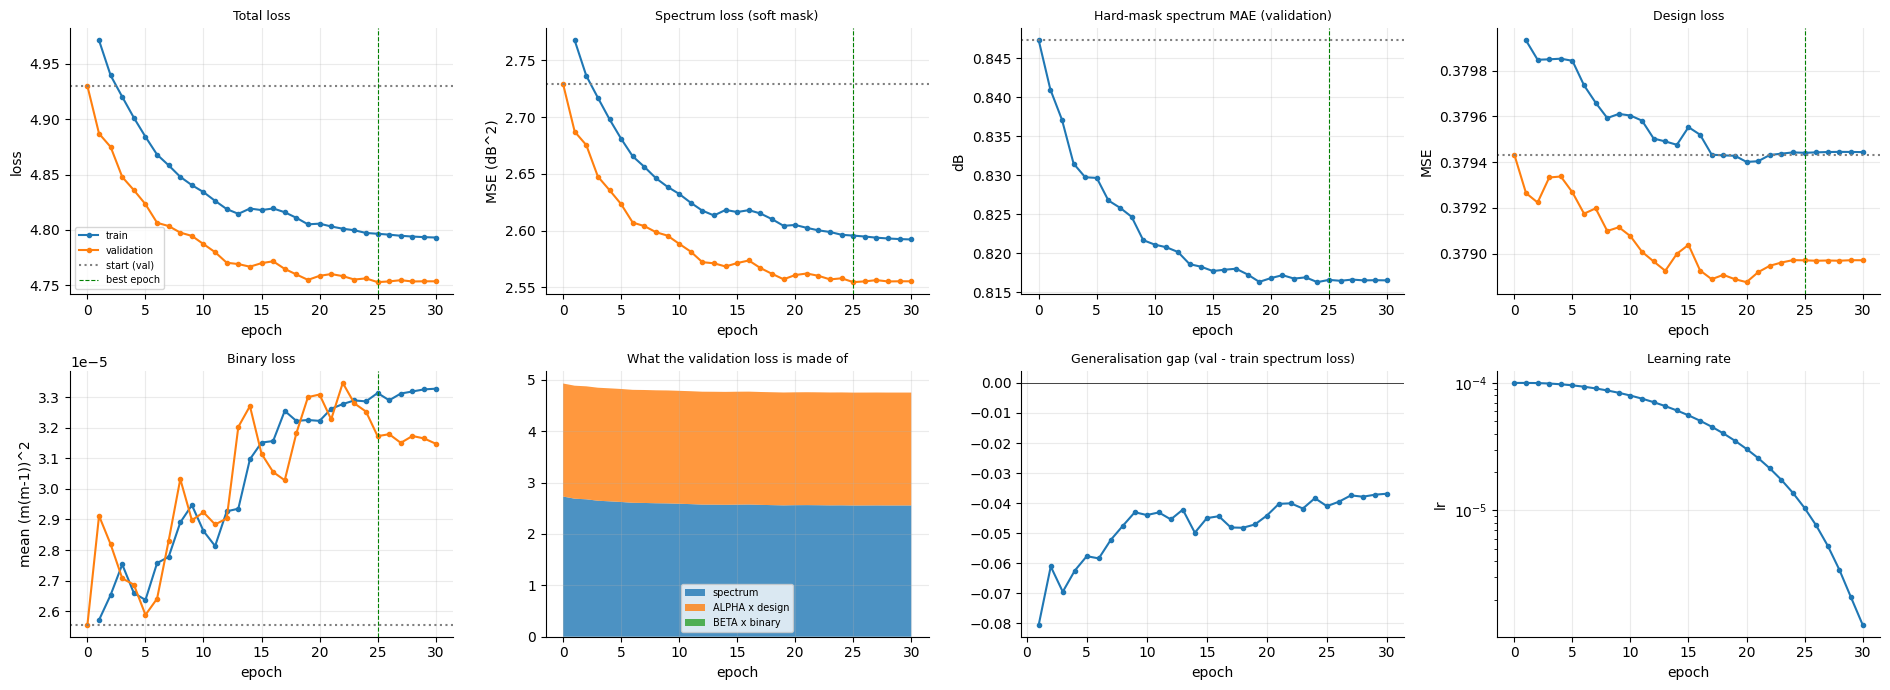

In [67]:
# ---- loss components: did the SPECTRUM actually improve, or only the design term?
th = train_hist
chk = pd.DataFrame({"start": [v0[0], v0[1], v0[4], v0[2], v0[3]]},
                   index=["val total loss", "val spectrum loss (MSE, dB^2)", "val hard-mask spectrum MAE (dB)", "val design loss", "val binary loss"])
bv = th[th.epoch == best_epoch].iloc[0]
chk["best epoch (%d)" % best_epoch] = [bv.val_loss, bv.val_spec, bv.val_spec_bin_mae, bv.val_design, bv.val_binary]
chk["change_%"] = 100 * (chk.iloc[:, 1] - chk.iloc[:, 0]) / chk.iloc[:, 0]
print(chk.round(5).to_string())
if best_epoch > 0:
    if bv.val_spec < v0[1] and bv.val_spec_bin_mae < v0[4]:
        print("\nThe SPECTRUM improved (soft-mask loss and hard-mask MAE both down), not just the design term.")
    elif bv.val_spec >= v0[1]:
        print("\nWARNING: the total loss improved but the spectrum loss did NOT. The gain comes from the design/binary terms. Consider SELECT_BY='spec' or 'spec_bin_mae'.")
    else:
        print("\nNote: the soft-mask spectrum loss improved but the hard-mask MAE did not, so binarisation is eating the gain (see the binary loss).")
w = th.copy(); w["val_w_design"] = CFG["ALPHA"] * w.val_design; w["val_w_binary"] = CFG["BETA"] * w.val_binary
w["train_w_design"] = CFG["ALPHA"] * w.train_design; w["train_w_binary"] = CFG["BETA"] * w.train_binary
print("\nShare of each term in the validation loss (start -> best): spectrum %.0f%% -> %.0f%% | ALPHA*design %.0f%% -> %.0f%% | BETA*binary %.0f%% -> %.0f%%" % (
    100 * w.val_spec.iloc[0] / w.val_loss.iloc[0], 100 * w.val_spec[w.epoch == best_epoch].iloc[0] / w.val_loss[w.epoch == best_epoch].iloc[0],
    100 * w.val_w_design.iloc[0] / w.val_loss.iloc[0], 100 * w.val_w_design[w.epoch == best_epoch].iloc[0] / w.val_loss[w.epoch == best_epoch].iloc[0],
    100 * w.val_w_binary.iloc[0] / w.val_loss.iloc[0], 100 * w.val_w_binary[w.epoch == best_epoch].iloc[0] / w.val_loss[w.epoch == best_epoch].iloc[0]))

fig, ax = plt.subplots(2, 4, figsize=(19, 7)); ax = ax.ravel()
def two(a, tcol, vcol, title, ylabel):
    if tcol: a.plot(th.epoch, th[tcol], "o-", ms=3, label="train")
    a.plot(th.epoch, th[vcol], "o-", ms=3, label="validation"); a.axhline(th[vcol].iloc[0], color="gray", ls=":", label="start (val)")
    a.axvline(best_epoch, color="green", ls="--", lw=0.8, label="best epoch"); a.set_title(title, fontsize=9); a.set_xlabel("epoch"); a.set_ylabel(ylabel)
two(ax[0], "train_loss", "val_loss", "Total loss", "loss"); ax[0].legend(fontsize=7)
two(ax[1], "train_spec", "val_spec", "Spectrum loss (soft mask)", "MSE (dB^2)")
two(ax[2], None, "val_spec_bin_mae", "Hard-mask spectrum MAE (validation)", "dB")
two(ax[3], "train_design", "val_design", "Design loss", "MSE")
two(ax[4], "train_binary", "val_binary", "Binary loss", "mean (m(m-1))^2")
ax[5].stackplot(w.epoch, w.val_spec, w.val_w_design, w.val_w_binary, labels=["spectrum", "ALPHA x design", "BETA x binary"], alpha=0.8)
ax[5].set_title("What the validation loss is made of", fontsize=9); ax[5].set_xlabel("epoch"); ax[5].legend(fontsize=7)
ax[6].plot(th.epoch, th.val_spec - th.train_spec, "o-", ms=3); ax[6].axhline(0, color="k", lw=0.5); ax[6].set_title("Generalisation gap (val - train spectrum loss)", fontsize=9); ax[6].set_xlabel("epoch")
ax[7].semilogy(th.epoch, th.lr, "o-", ms=3); ax[7].set_title("Learning rate", fontsize=9); ax[7].set_xlabel("epoch"); ax[7].set_ylabel("lr")
save_show("training_curves")
chk.round(5).to_csv(f"{OUT_DIR}/loss_components_start_vs_best.csv")

### 8b. Optional ablations (set `RUN_ABLATION = True` in the config)
Short runs of variants, scored on the same held-out test set. Use this to justify your hyper-parameter choices in the viva.

In [68]:
if RUN_ABLATION:
    rows = []
    def row(name, model):
        d = evaluate(model, test_res)
        return {"variant": name, "in_band_success_%": 100 * d.success[is_in].mean(), "in_band_median_res_err": d.res_err[is_in].median(),
                "outside_success_%": 100 * d.success[~is_in].mean(), "outside_median_res_err": d.res_err[~is_in].median()}
    rows.append(row("previous model (no fine-tuning)", prev_model)); rows.append(row("main run", inv))
    for name, over in ABLATIONS.items():
        cfg2 = {**CFG, **over, "EPOCHS": min(CFG["EPOCHS"], ABL_EPOCHS)}
        sets2 = SETS if cfg2["REPLAY_FRAC"] == CFG["REPLAY_FRAC"] else build_sets(cfg2)
        m2, h2, v02, b2, _, _ = finetune(cfg2, sets2, save_path=None, verbose=False)
        rows.append({**row(name, m2), "val_selection_metric": b2}); print("done:", name)
        del m2; torch.cuda.empty_cache()
    abl_df = pd.DataFrame(rows).round(3); abl_df.to_csv(f"{OUT_DIR}/ablation.csv", index=False); print(abl_df.to_string(index=False))
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
    ax[0].barh(abl_df.variant, abl_df["in_band_success_%"], color="tab:blue"); ax[0].set_xlabel("in-band success (%)"); ax[0].set_title("Ablation: in band")
    ax[1].barh(abl_df.variant, abl_df["outside_success_%"], color="tab:gray"); ax[1].set_xlabel("outside-band success (%)"); ax[1].set_title("Ablation: outside band (forgetting)")
    save_show("ablation")
else:
    print("Ablations skipped (RUN_ABLATION = False).")

Ablations skipped (RUN_ABLATION = False).


## 9. Compare models on the held-out test set
Same leak-free test set for every model. Check both: **in-band** (should improve) and **outside the band** (watch for forgetting).

                                             n  success_%  legacy_success_%  median_res_err_GHz  mean_res_err_GHz  spec_MAE_dB  dip_depth_err_dB  bw_err_GHz
model               subset                                                                                                                                  
Original            in band 13-17 GHz  15200.0     70.507            67.691                0.00             0.457        0.871             5.281       0.151
                    outside band        9691.0     10.855            10.154                0.25             1.111        1.025            10.162       0.213
Previous fine-tuned in band 13-17 GHz  15200.0     68.500            66.099                0.00             0.444        0.841             5.274       0.149
                    outside band        9691.0     13.126            12.537                0.25             1.067        1.008             9.973       0.209
New in-band         in band 13-17 GHz  15200.0     64.197 

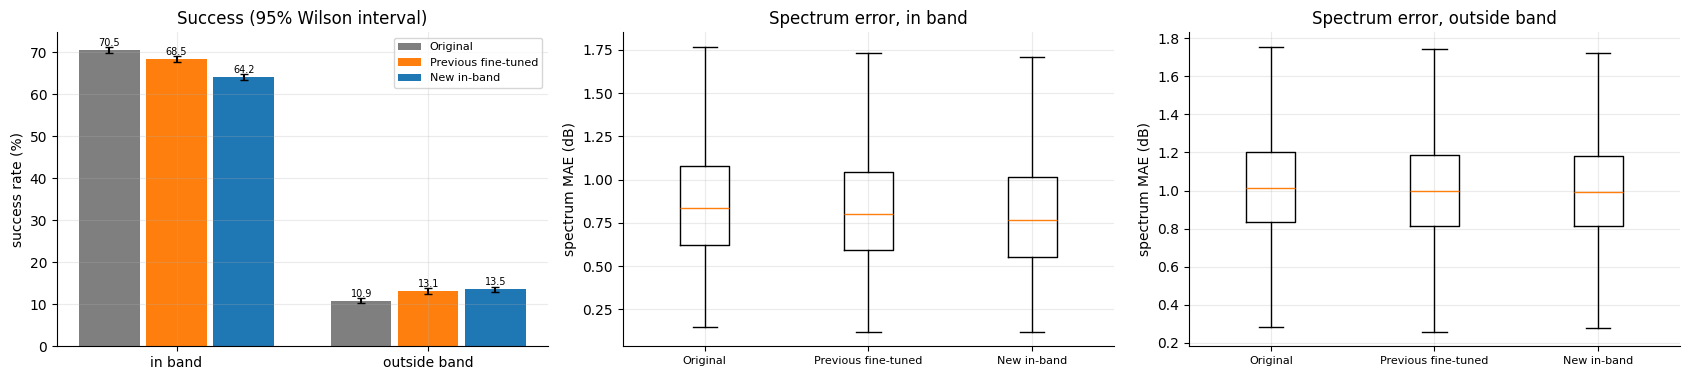

In [69]:
models = {"Previous fine-tuned": prev_model, "New in-band": inv}
if orig_model is not None: models = {"Original": orig_model, **models}
COL = {"Original": "tab:gray", "Previous fine-tuned": "tab:orange", "New in-band": "tab:blue"}

dfs = {name: evaluate(m, test_res, key=name) for name, m in models.items()}
rows = []
for name, d in dfs.items():
    rows.append(pd.concat([pd.Series({"model": name, "subset": "in band %.0f-%.0f GHz" % (LO, HI)}), summarize(d[is_in])]))
    rows.append(pd.concat([pd.Series({"model": name, "subset": "outside band"}), summarize(d[~is_in])]))
cmp_df = pd.DataFrame(rows).set_index(["model", "subset"]).round(3)
cmp_df.to_csv(f"{OUT_DIR}/model_comparison.csv"); print(cmp_df.to_string())

print("\nFailure types in band (percent of in-band resonant test designs):")
ft = pd.DataFrame({n: failure_types(d[is_in]) for n, d in dfs.items()}).T.round(1); print(ft.to_string())
print("\nFailure types outside band:")
ft_out = pd.DataFrame({n: failure_types(d[~is_in]) for n, d in dfs.items()}).T.round(1); print(ft_out.to_string())
ft.to_csv(f"{OUT_DIR}/failure_types_in_band.csv"); ft_out.to_csv(f"{OUT_DIR}/failure_types_outside_band.csv")

print("\nBinarisation (soft vs binary mask) on 5000 test designs:")
sb = pd.DataFrame({n: dict(zip(["spectrum_diff_dB", "pixels_not_binary_%"], soft_binary_gap(m, test_res[:5000]))) for n, m in models.items()}).T.round(3)
print(sb.to_string())

def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan, np.nan)
    p = k / n; den = 1 + z * z / n; c = (p + z * z / (2 * n)) / den; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return 100 * p, 100 * (c - h), 100 * (c + h)

fig, ax = plt.subplots(1, 3, figsize=(17, 3.9))
names = list(dfs); xs = np.arange(2); wd = 0.8 / len(names)
for j, n in enumerate(names):
    for i, m in enumerate([is_in, ~is_in]):
        p, lo_, hi_ = wilson(int(dfs[n].success.values[m].sum()), int(m.sum()))
        ax[0].bar(xs[i] + j * wd, p, width=wd * 0.9, color=COL.get(n), label=n if i == 0 else None, yerr=[[p - lo_], [hi_ - p]], capsize=3)
        ax[0].text(xs[i] + j * wd, p + 1, "%.1f" % p, ha="center", fontsize=7)
ax[0].set_xticks(xs + wd * (len(names) - 1) / 2); ax[0].set_xticklabels(["in band", "outside band"]); ax[0].set_ylabel("success rate (%)"); ax[0].legend(fontsize=8); ax[0].set_title("Success (95% Wilson interval)")
data_in = [dfs[n].spec_mae.values[is_in] for n in names]; data_out = [dfs[n].spec_mae.values[~is_in] for n in names]
for a, data, t in [(ax[1], data_in, "in band"), (ax[2], data_out, "outside band")]:
    a.boxplot(data, showfliers=False); a.set_xticks(range(1, len(names) + 1)); a.set_xticklabels(names, fontsize=8); a.set_ylabel("spectrum MAE (dB)"); a.set_title("Spectrum error, " + t)
save_show("model_comparison_summary")

in band       | success change (new - previous): -4.30 pp  [95% CI -4.78, -3.84] | designs fixed: 350, designs broken: 1004 (n=15200)
outside band  | success change (new - previous): +0.40 pp  [95% CI +0.14, +0.68] | designs fixed: 102, designs broken: 63 (n=9691)


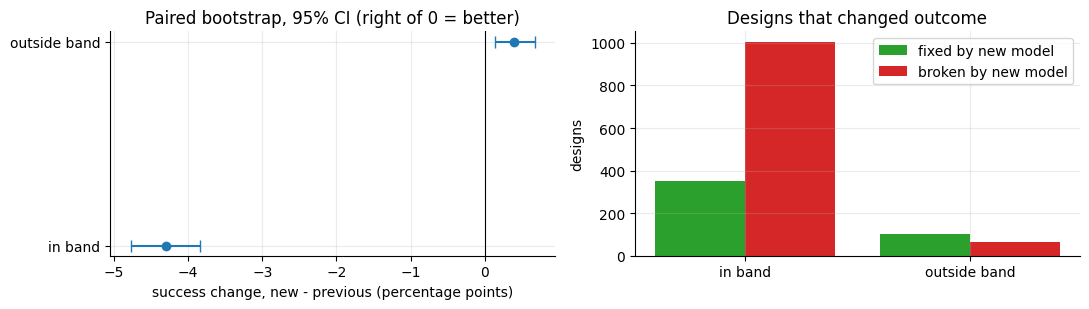

In [70]:
# Is the in-band improvement real? Paired bootstrap over the test designs (95% interval of the difference in success rate)
def paired_bootstrap(a, b, n=2000, seed=0):
    k = len(a)
    if k == 0: return np.nan, np.nan, np.nan
    rng = np.random.default_rng(seed); d = []
    for _ in range(max(1, n // 100)):
        ii = rng.integers(0, k, (100, k)); d.append(b[ii].mean(1) - a[ii].mean(1))
    d = np.concatenate(d)
    return 100 * d.mean(), 100 * np.percentile(d, 2.5), 100 * np.percentile(d, 97.5)

a_prev = dfs["Previous fine-tuned"].success.values.astype(float); b_new = dfs["New in-band"].success.values.astype(float)
boot = {}
for label, m in [("in band", is_in), ("outside band", ~is_in)]:
    mean_d, lo_, hi_ = paired_bootstrap(a_prev[m], b_new[m]); boot[label] = (mean_d, lo_, hi_)
    wins = int(((b_new[m] == 1) & (a_prev[m] == 0)).sum()); losses = int(((b_new[m] == 0) & (a_prev[m] == 1)).sum())
    print("%-13s | success change (new - previous): %+.2f pp  [95%% CI %+.2f, %+.2f] | designs fixed: %d, designs broken: %d (n=%d)" %
          (label, mean_d, lo_, hi_, wins, losses, int(m.sum())))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for i, (label, (md_, lo_, hi_)) in enumerate(boot.items()):
    ax[0].errorbar(md_, i, xerr=[[md_ - lo_], [hi_ - md_]], fmt="o", color="tab:blue", capsize=4)
ax[0].axvline(0, color="k", lw=0.8); ax[0].set_yticks(range(len(boot))); ax[0].set_yticklabels(list(boot)); ax[0].set_xlabel("success change, new - previous (percentage points)"); ax[0].set_title("Paired bootstrap, 95% CI (right of 0 = better)")
fx = [int(((b_new[m] == 1) & (a_prev[m] == 0)).sum()) for m in [is_in, ~is_in]]; bk = [int(((b_new[m] == 0) & (a_prev[m] == 1)).sum()) for m in [is_in, ~is_in]]
ax[1].bar(np.arange(2) - 0.2, fx, width=0.4, color="tab:green", label="fixed by new model"); ax[1].bar(np.arange(2) + 0.2, bk, width=0.4, color="tab:red", label="broken by new model")
ax[1].set_xticks(range(2)); ax[1].set_xticklabels(["in band", "outside band"]); ax[1].set_ylabel("designs"); ax[1].legend(); ax[1].set_title("Designs that changed outcome")
save_show("bootstrap_and_flips")

 bin_start_GHz  n_test  Original success_%  Original median_res_err_GHz  Previous fine-tuned success_%  Previous fine-tuned median_res_err_GHz  New in-band success_%  New in-band median_res_err_GHz  delta_success_pp (new - previous)
          10.0      42                 0.0                          6.8                            0.0                                     6.7                    0.0                             6.8                                0.0
          10.5      72                 0.0                          6.0                            0.0                                     5.9                    0.0                             6.0                                0.0
          11.0     139                 0.0                          5.6                            0.0                                     5.6                    0.0                             5.5                                0.0
          11.5     227                 0.0                          

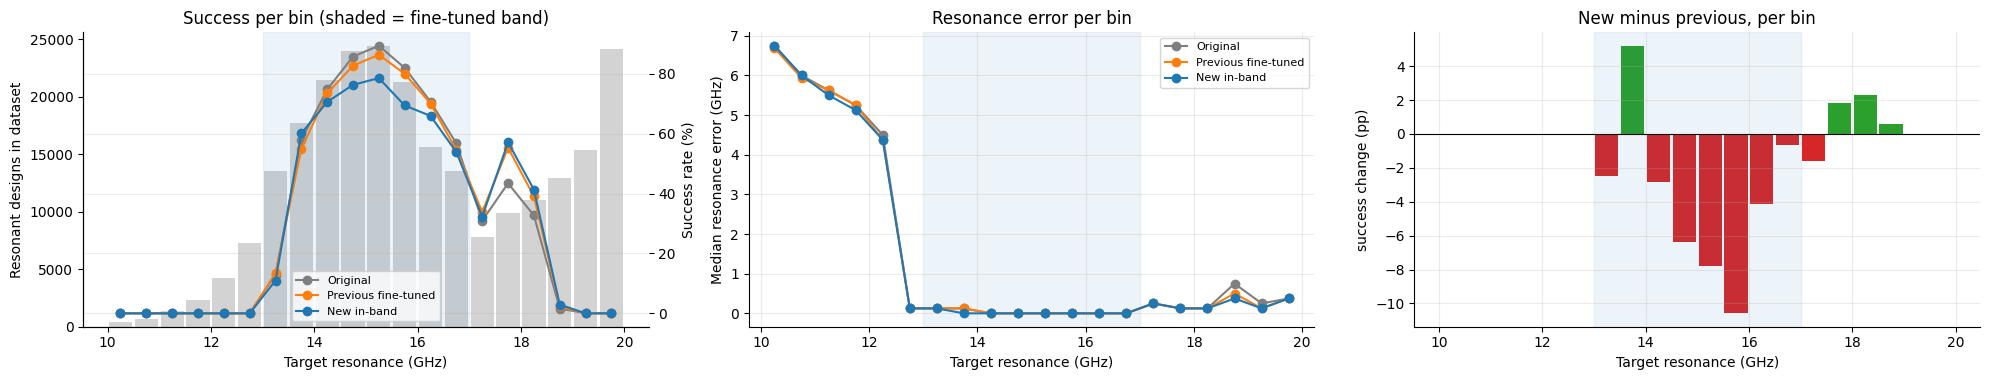

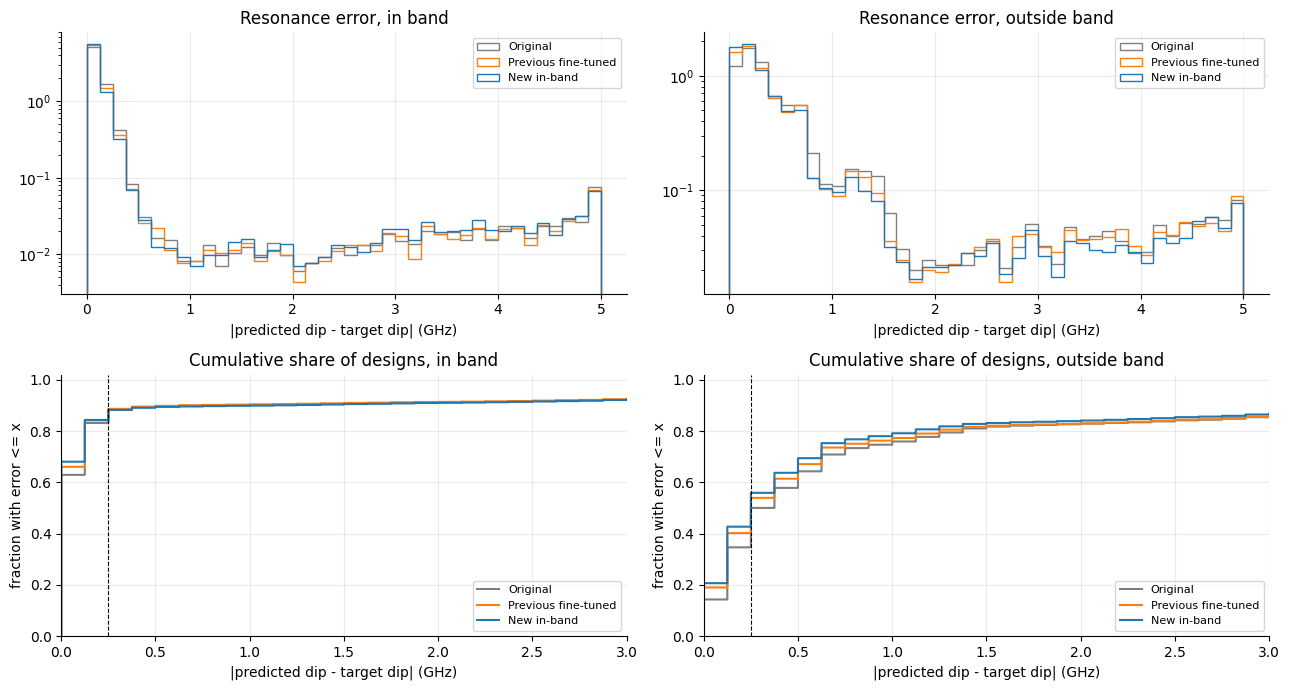

In [71]:
# Per-bin comparison tables and plots
pb = pd.DataFrame({"bin_start_GHz": edges})
for n, d in dfs.items():
    t = per_bin_table(d)
    pb["n_test"] = t["n"].values
    pb[f"{n} success_%"] = t["success_%"].values; pb[f"{n} median_res_err_GHz"] = t["median_res_err_GHz"].values
pb["delta_success_pp (new - previous)"] = pb["New in-band success_%"] - pb["Previous fine-tuned success_%"]
pb.round(2).to_csv(f"{OUT_DIR}/per_bin_comparison.csv", index=False); print(pb.round(1).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(20, 3.9)); ax2 = ax[0].twinx()
ax[0].bar(edges + BIN_W / 2, cnt, width=BIN_W * 0.9, color="lightgray"); ax[0].set_ylabel("Resonant designs in dataset"); ax[0].grid(False)
for name, d in dfs.items():
    t = per_bin_table(d); ax2.plot(edges + BIN_W / 2, t["success_%"].values, "o-", color=COL.get(name), label=name)
    ax[1].plot(edges + BIN_W / 2, t["median_res_err_GHz"].values, "o-", color=COL.get(name), label=name)
dlt = pb["delta_success_pp (new - previous)"].values
ax[2].bar(edges + BIN_W / 2, np.nan_to_num(dlt), width=BIN_W * 0.9, color=np.where(np.nan_to_num(dlt) >= 0, "tab:green", "tab:red")); ax[2].axhline(0, color="k", lw=0.8)
ax[2].set_ylabel("success change (pp)"); ax[2].set_title("New minus previous, per bin")
for a in ax: a.axvspan(LO, HI, color="tab:blue", alpha=0.08); a.set_xlabel("Target resonance (GHz)")
ax2.set_ylabel("Success rate (%)"); ax2.legend(loc="lower center", fontsize=8); ax[1].set_ylabel("Median resonance error (GHz)"); ax[1].legend(fontsize=8)
ax[0].set_title("Success per bin (shaded = fine-tuned band)"); ax[1].set_title("Resonance error per bin")
save_show("success_per_bin")

fig, ax = plt.subplots(2, 2, figsize=(13, 7))
for name, d in dfs.items():
    for j, (m, t) in enumerate([(is_in, "in band"), (~is_in, "outside band")]):
        v = d.res_err.values[m]
        ax[0, j].hist(v, bins=np.arange(0, 5.01, 0.125), histtype="step", label=name, density=True, color=COL.get(name))
        xx = np.sort(v); ax[1, j].step(xx, np.arange(1, len(xx) + 1) / max(1, len(xx)), where="post", label=name, color=COL.get(name))
        ax[0, j].set_title("Resonance error, " + t); ax[0, j].set_yscale("log"); ax[1, j].set_title("Cumulative share of designs, " + t)
for a in ax[1]: a.axvline(CFG["TOL_GHZ"], color="k", ls="--", lw=0.8); a.set_xlim(0, 3); a.set_ylim(0, 1.02); a.set_ylabel("fraction with error <= x")
for a in ax.ravel(): a.set_xlabel("|predicted dip - target dip| (GHz)"); a.legend(fontsize=8)
save_show("resonance_error_hist_ecdf")

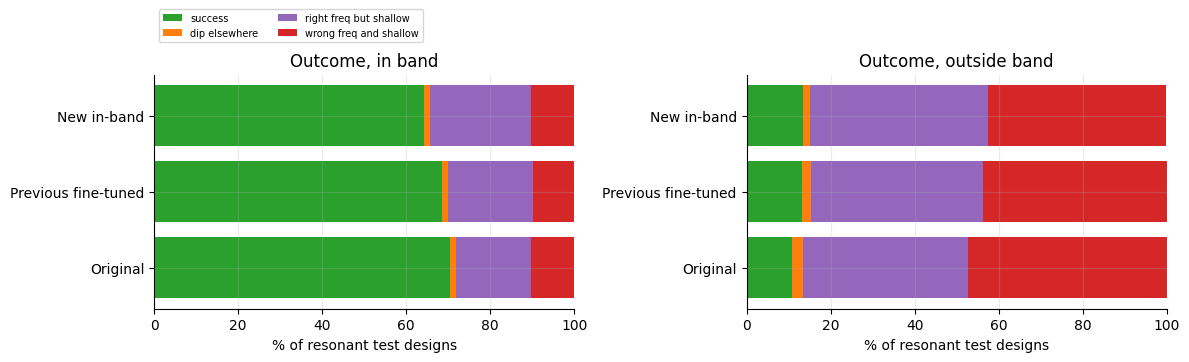

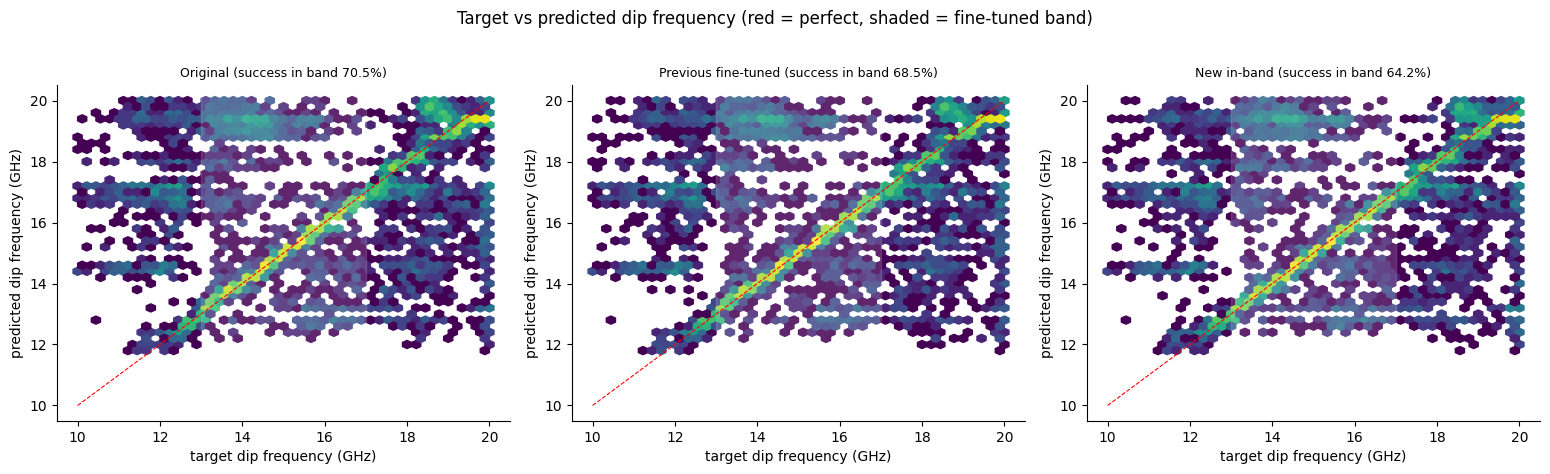

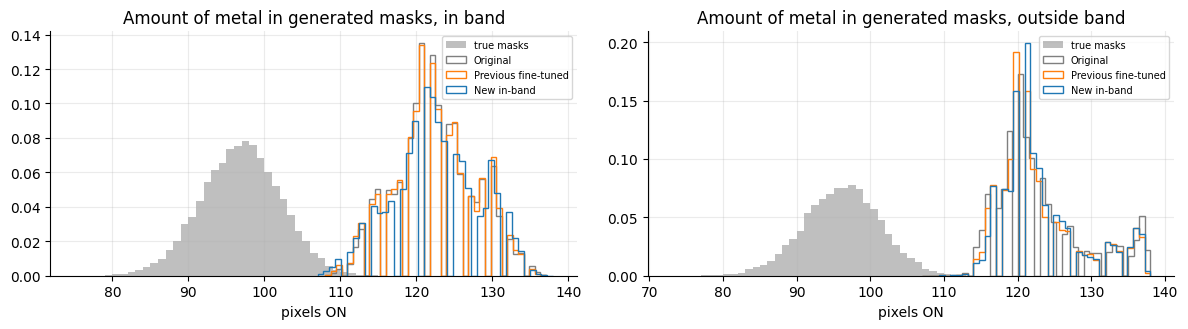

In [72]:
# Failure types, target vs predicted frequency, predicted metal amount
cats = ["success_%", "dip_elsewhere_%", "right_freq_but_shallow_%", "wrong_freq_and_shallow_%"]
cat_col = ["tab:green", "tab:orange", "tab:purple", "tab:red"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, tab, t in [(ax[0], ft, "in band"), (ax[1], ft_out, "outside band")]:
    left = np.zeros(len(tab))
    for c, col in zip(cats, cat_col):
        a.barh(tab.index, tab[c].values, left=left, color=col, label=c.replace("_%", "").replace("_", " ")); left += tab[c].values
    a.set_xlabel("% of resonant test designs"); a.set_title("Outcome, " + t); a.set_xlim(0, 100)
ax[0].legend(fontsize=7, loc="lower left", bbox_to_anchor=(0, 1.12), ncol=2)
save_show("failure_types")

fig, ax = plt.subplots(1, len(dfs), figsize=(5.2 * len(dfs), 4.6), squeeze=False)
for a, (name, d) in zip(ax[0], dfs.items()):
    hb = a.hexbin(d.tgt_f, d.pred_f, gridsize=45, bins="log", cmap="viridis", mincnt=1, extent=(10, 20, 10, 20))
    a.plot([10, 20], [10, 20], "r--", lw=0.8); a.axvspan(LO, HI, color="white", alpha=0.15); a.set_xlabel("target dip frequency (GHz)"); a.set_ylabel("predicted dip frequency (GHz)")
    a.set_title(name + " (success in band %.1f%%)" % (100 * d.success[is_in].mean()), fontsize=9); a.grid(False)
plt.suptitle("Target vs predicted dip frequency (red = perfect, shaded = fine-tuned band)", y=1.02)
save_show("target_vs_predicted_frequency")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
for j, (m, t) in enumerate([(is_in, "in band"), (~is_in, "outside band")]):
    ax[j].hist(X[test_res][m].sum(1), bins=40, density=True, histtype="stepfilled", alpha=0.25, color="k", label="true masks")
    for name in dfs: ax[j].hist(PRED[name][1][m].sum(1), bins=40, density=True, histtype="step", color=COL.get(name), label=name)
    ax[j].set_xlabel("pixels ON"); ax[j].set_title("Amount of metal in generated masks, " + t); ax[j].legend(fontsize=7)
save_show("pixels_on_generated_masks")

Full leak-free test set (67748 designs):
                     Spectrum_MAE_dB  Resonance_Error_GHz  Minimum_S11_Error_dB
Original                     0.67129              1.17615               3.62374
Previous fine-tuned          0.64813              1.16143               3.57231
New in-band                  0.64027              1.17759               3.59862


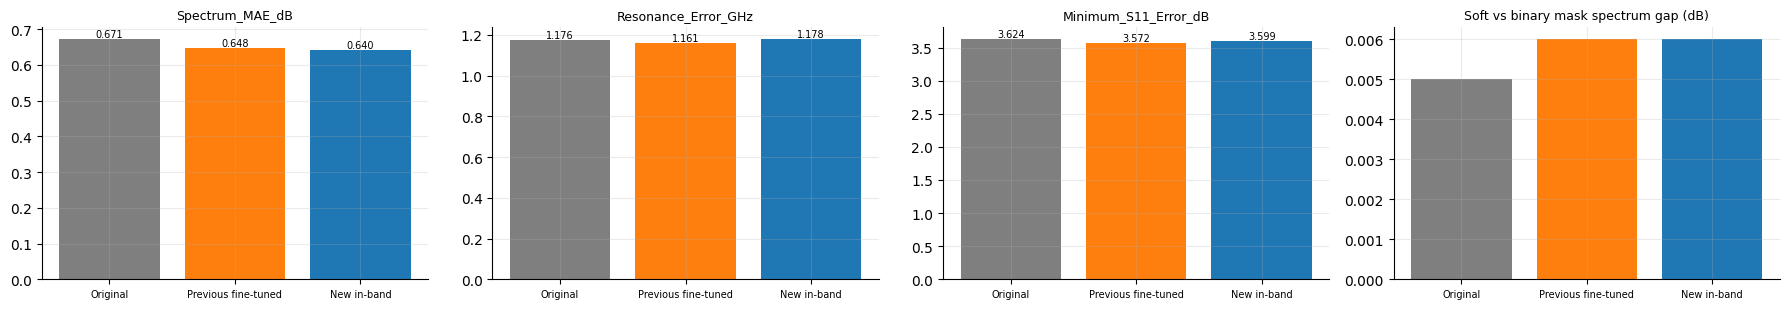

In [73]:
# Full test set (resonant and non-resonant) with the same metrics as in your earlier notebook, to catch an overall regression
def full_metrics(model):
    P, _ = predict_spectra(model, Y[test_idx]); T = Y[test_idx]
    return {"Spectrum_MAE_dB": np.abs(P - T).mean(),
            "Resonance_Error_GHz": np.abs(freq[P.argmin(1)] - freq[T.argmin(1)]).mean(),
            "Minimum_S11_Error_dB": np.abs(P.min(1) - T.min(1)).mean()}
full_df = pd.DataFrame({n: full_metrics(m) for n, m in models.items()}).T.round(5)
full_df.to_csv(f"{OUT_DIR}/full_test_metrics.csv"); print("Full leak-free test set (%d designs):" % len(test_idx)); print(full_df.to_string())

fig, ax = plt.subplots(1, 4, figsize=(18, 3.2))
for a, c in zip(ax[:3], full_df.columns):
    a.bar(full_df.index, full_df[c], color=[COL.get(n) for n in full_df.index]); a.set_title(c, fontsize=9); a.tick_params(axis="x", labelsize=7)
    for i, v in enumerate(full_df[c]): a.text(i, v, "%.3f" % v, ha="center", va="bottom", fontsize=7)
ax[3].bar(sb.index, sb["spectrum_diff_dB"], color=[COL.get(n) for n in sb.index]); ax[3].set_title("Soft vs binary mask spectrum gap (dB)", fontsize=9); ax[3].tick_params(axis="x", labelsize=7)
save_show("full_test_metrics")

Original test split: 24891 resonant rows, of which 0 (0.0%) have a mask that was also in the original train/val split
              model       subset                           group     n  success_%  median_res_err_GHz
           Original      in band leaked (mask also in train/val)     0        NaN                 NaN
           Original      in band           clean (mask not seen) 15200      70.51                0.00
           Original outside band leaked (mask also in train/val)     0        NaN                 NaN
           Original outside band           clean (mask not seen)  9691      10.86                0.25
Previous fine-tuned      in band leaked (mask also in train/val)     0        NaN                 NaN
Previous fine-tuned      in band           clean (mask not seen) 15200      68.50                0.00
Previous fine-tuned outside band leaked (mask also in train/val)     0        NaN                 NaN
Previous fine-tuned outside band           clean (mask not seen)  

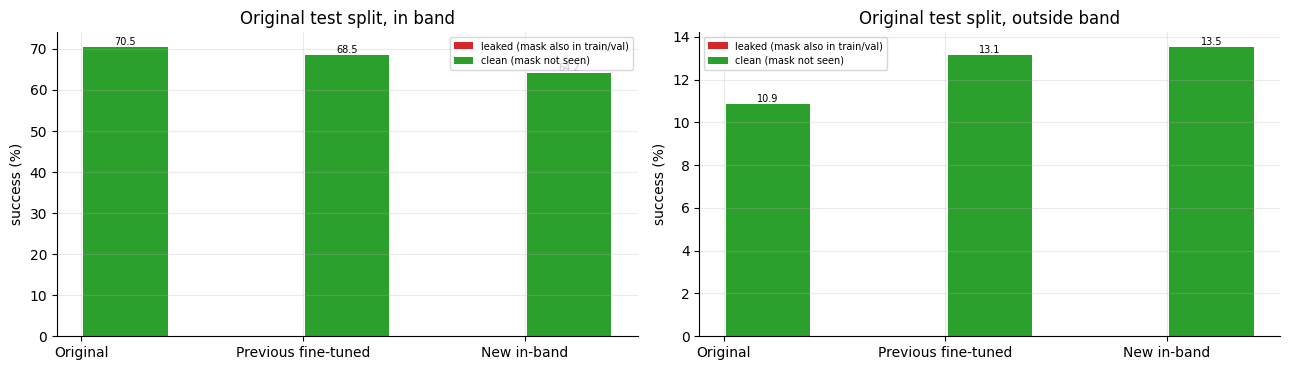

If the red bars are clearly higher than the green ones, the earlier numbers on the original split were inflated by duplicate masks.


In [74]:
# How much did the duplicate leakage inflate the NUMBERS YOU HAD BEFORE?
# Score every model on the ORIGINAL test split and separate rows whose mask was also in the original training/validation split ("leaked") from clean rows.
t0_res_mask = res_any[test0]
test0_res = test0[t0_res_mask]; leaked0 = leak_test0[t0_res_mask]; in0 = res_in[test0_res]
rows = []
for name, m in models.items():
    d0 = evaluate(m, test0_res)
    for sub, sm in [("in band", in0), ("outside band", ~in0)]:
        for grp, gm in [("leaked (mask also in train/val)", leaked0), ("clean (mask not seen)", ~leaked0)]:
            s = sm & gm
            rows.append({"model": name, "subset": sub, "group": grp, "n": int(s.sum()), "success_%": 100 * d0.success.values[s].mean() if s.any() else np.nan,
                         "median_res_err_GHz": float(np.median(d0.res_err.values[s])) if s.any() else np.nan})
leak_tab = pd.DataFrame(rows).round(2); leak_tab.to_csv(f"{OUT_DIR}/leakage_effect.csv", index=False)
print("Original test split: %d resonant rows, of which %d (%.1f%%) have a mask that was also in the original train/val split" % (len(test0_res), leaked0.sum(), 100 * leaked0.mean()))
print(leak_tab.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, sub in zip(ax, ["in band", "outside band"]):
    t = leak_tab[leak_tab["subset"] == sub]; xs_ = np.arange(len(models))
    for j, grp in enumerate(["leaked (mask also in train/val)", "clean (mask not seen)"]):
        vv = [t[(t.model == n) & (t.group == grp)]["success_%"].values[0] for n in models]
        a.bar(xs_ + j * 0.4, vv, width=0.38, color=["tab:red", "tab:green"][j], label=grp)
        for x_, v_ in zip(xs_ + j * 0.4, vv): a.text(x_, v_, "%.1f" % v_, ha="center", va="bottom", fontsize=7)
    a.set_xticks(xs_ + 0.2); a.set_xticklabels(list(models)); a.set_ylabel("success (%)"); a.set_title("Original test split, " + sub); a.legend(fontsize=7)
save_show("leakage_effect")
print("If the red bars are clearly higher than the green ones, the earlier numbers on the original split were inflated by duplicate masks.")

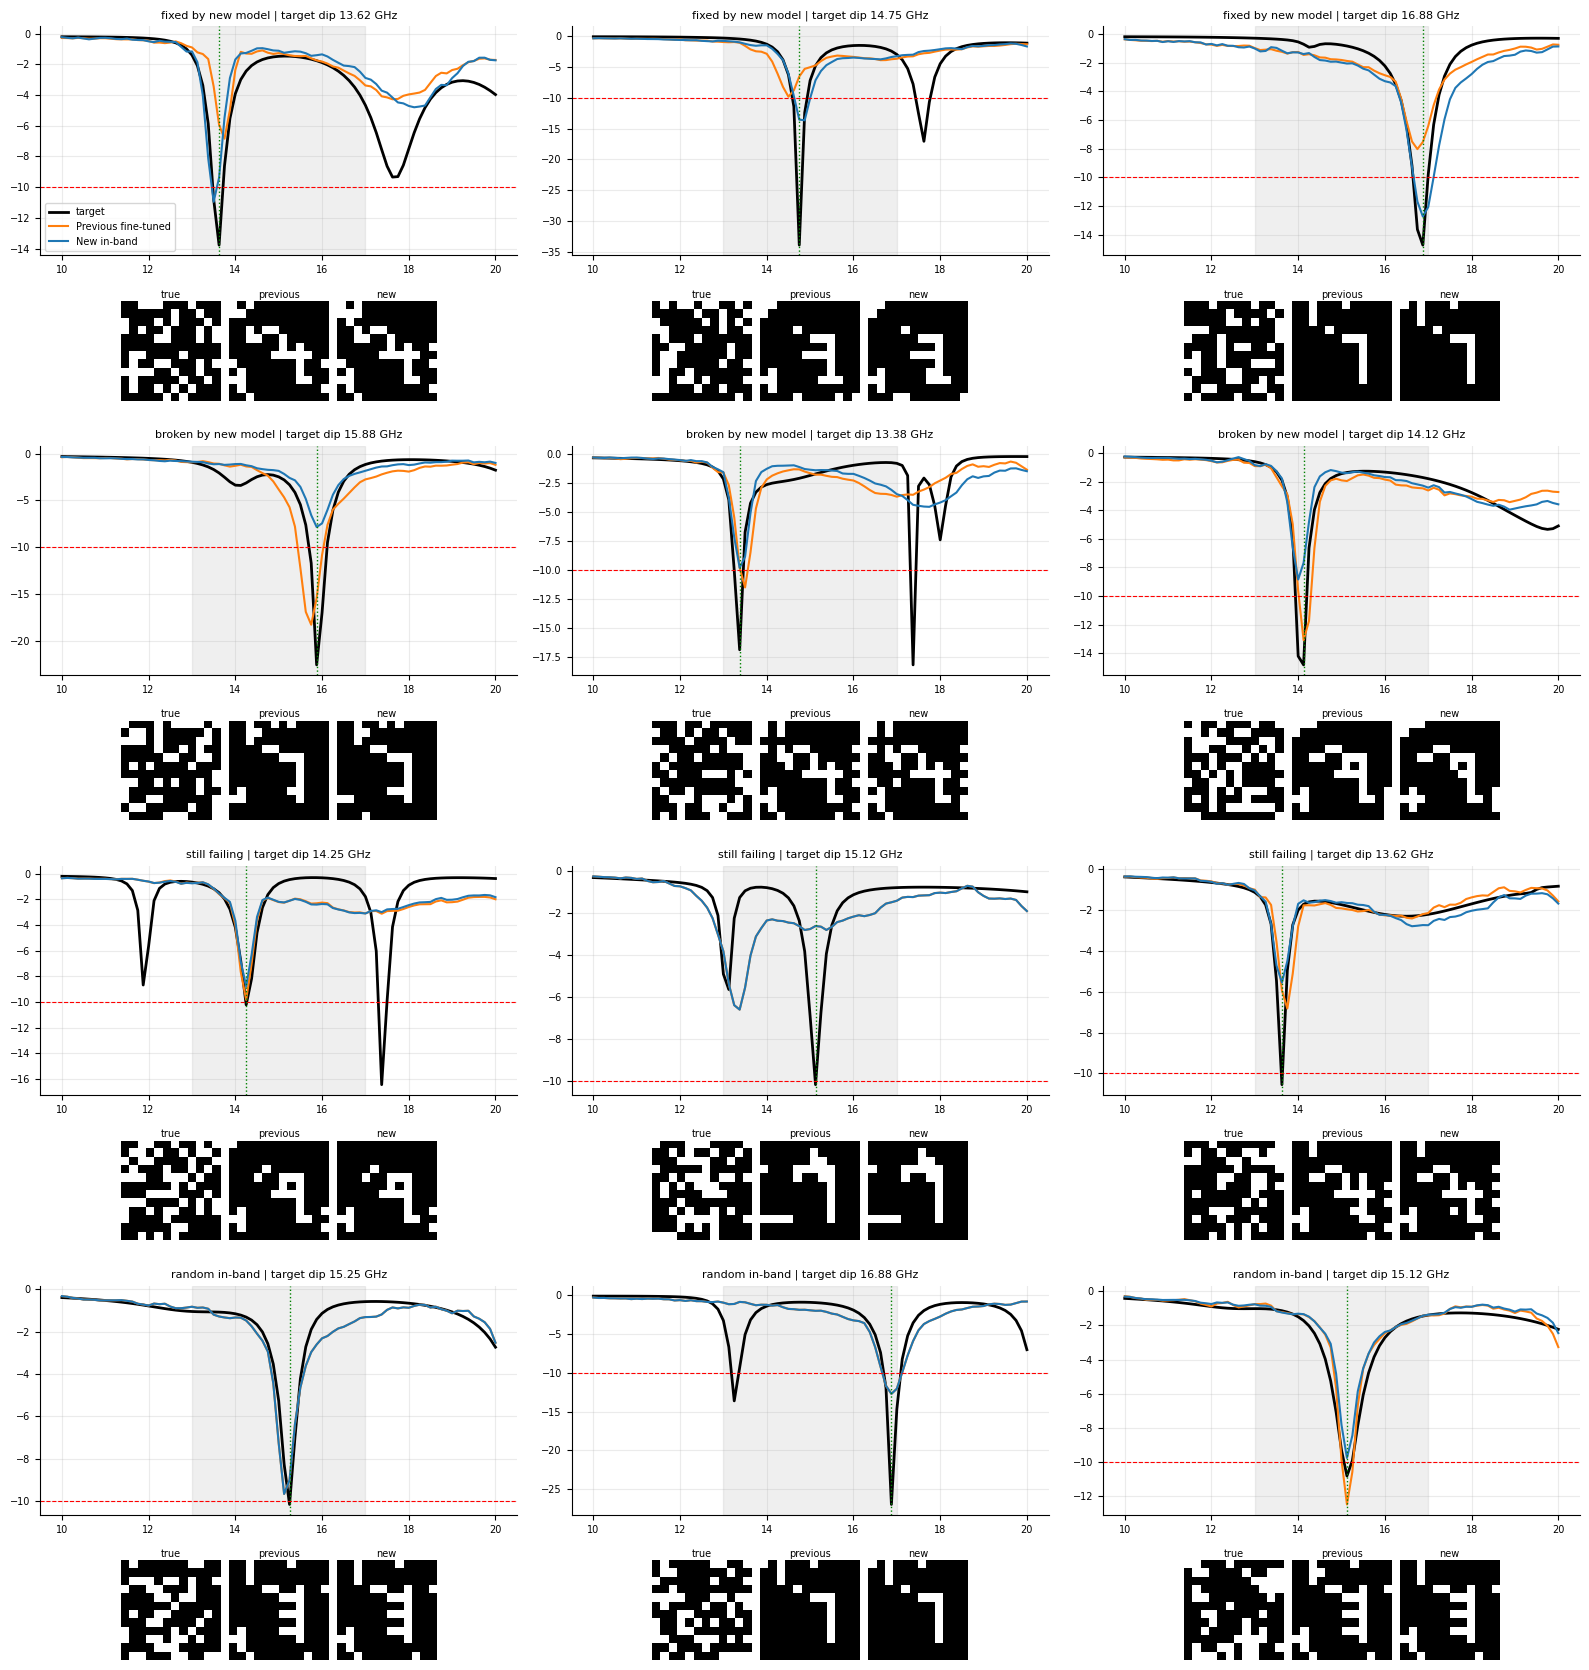

In [75]:
# Example designs: target vs previous vs new spectra, with the masks (true | previous | new)
a_s = dfs["Previous fine-tuned"].success.values; b_s = dfs["New in-band"].success.values
fixed = np.where(is_in & b_s & ~a_s)[0]; broken = np.where(is_in & ~b_s & a_s)[0]
still = np.where(is_in & ~b_s & ~a_s)[0]; rand_in = np.where(is_in)[0]
rng_e = np.random.default_rng(1)
ex_groups = [("fixed by new model", fixed), ("broken by new model", broken), ("still failing", still), ("random in-band", rand_in)]
ex = []
for title, arr in ex_groups:
    if len(arr): ex += [(title, int(i)) for i in rng_e.choice(arr, min(3, len(arr)), replace=False)]
nr = int(np.ceil(len(ex) / 3))
fig = plt.figure(figsize=(16, 4.2 * nr)); gs = fig.add_gridspec(2 * nr, 3, height_ratios=[2.3, 1.0] * nr)
for k, (title, i) in enumerate(ex):
    r, c = divmod(k, 3); a1 = fig.add_subplot(gs[2 * r, c]); a2 = fig.add_subplot(gs[2 * r + 1, c])
    a1.plot(freq, Y[test_res[i]], "k", lw=2, label="target")
    for name in ["Previous fine-tuned", "New in-band"]: a1.plot(freq, PRED[name][0][i], color=COL[name], label=name)
    a1.axhline(THRESH, color="r", ls="--", lw=0.8); a1.axvspan(LO, HI, color="gray", alpha=0.12); a1.axvline(dfs["New in-band"].tgt_f.values[i], color="g", ls=":", lw=1)
    a1.set_title("%s | target dip %.2f GHz" % (title, dfs["New in-band"].tgt_f.values[i]), fontsize=8); a1.tick_params(labelsize=7)
    if k == 0: a1.legend(fontsize=7)
    gap_col = np.full((12, 1), np.nan)
    strip = np.hstack([X[test_res[i]].reshape(12, 12), gap_col, PRED["Previous fine-tuned"][1][i].reshape(12, 12), gap_col, PRED["New in-band"][1][i].reshape(12, 12)])
    a2.imshow(np.ma.masked_invalid(strip), cmap="Greys", vmin=0, vmax=1, interpolation="nearest"); a2.axis("off")
    for xc, tx in [(5.5, "true"), (18.5, "previous"), (31.5, "new")]: a2.text(xc, -0.9, tx, ha="center", fontsize=7)
save_show("example_designs_prev_vs_new")

## 10. Fig. 9-style sweep: a 500 MHz notch moved across 10-20 GHz
Target spectrum as in the paper's synthetic test: `BASE_DB` outside, `DEPTH_DB` inside a `NOTCH_GHZ` wide notch. A target is a **Yes** if the forward-predicted spectrum of the generated mask has exactly one dip, with a point <= threshold within `TOL_GHZ` of the requested centre.

Original             | Yes in band:  87.5% | Yes outside band:  22.2% | Yes overall:  49.4%
   'No' ranges (GHz): ['10.25-13.38', '17.38-17.38', '18.38-19.75']
Previous fine-tuned  | Yes in band:  87.5% | Yes outside band:  22.2% | Yes overall:  49.4%
   'No' ranges (GHz): ['10.25-13.38', '17.38-17.38', '18.38-19.75']
New in-band          | Yes in band:  87.5% | Yes outside band:  22.2% | Yes overall:  49.4%
   'No' ranges (GHz): ['10.25-13.38', '17.38-17.38', '18.38-19.75']


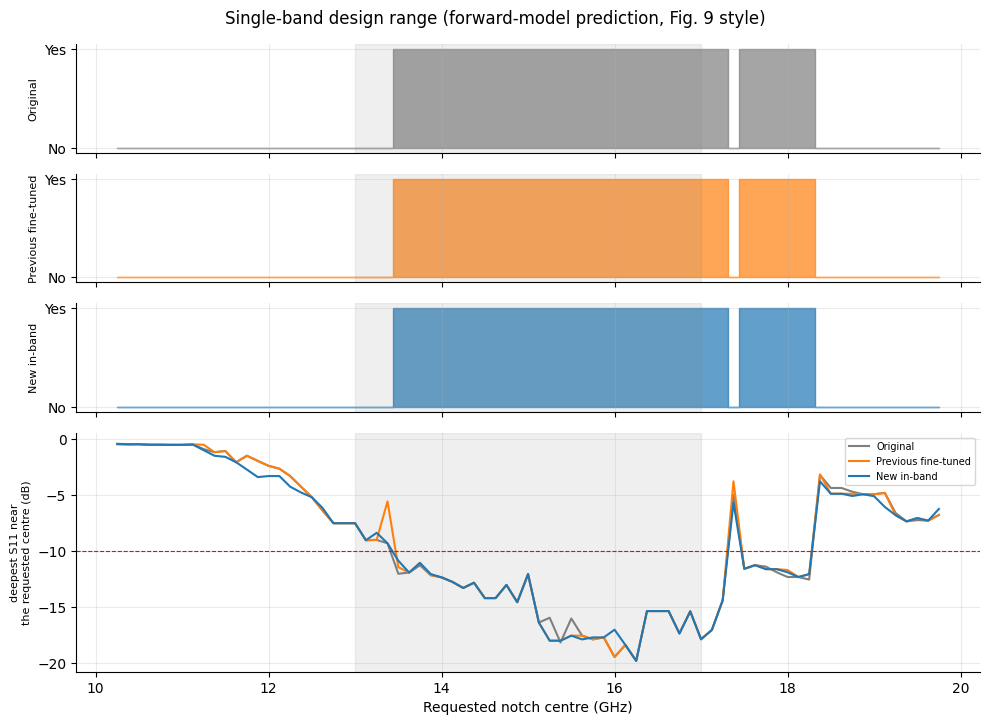

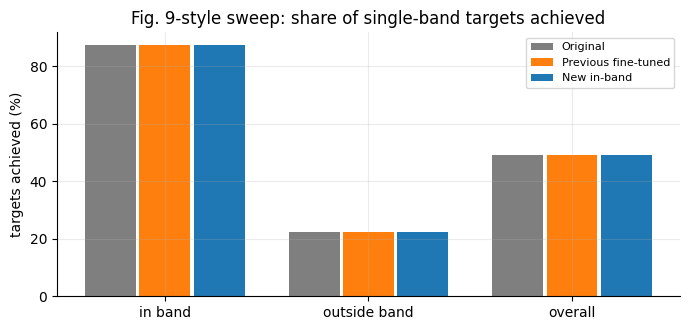

In [76]:
centers = np.round(np.arange(10.25, 19.75 + 1e-9, 0.125), 3)
def notch_target(c):
    s = np.full(81, CFG["BASE_DB"], dtype=np.float32)
    s[np.abs(freq - c) <= CFG["NOTCH_GHZ"] / 2 + 1e-9] = CFG["DEPTH_DB"]
    return s
T = np.stack([notch_target(c) for c in centers])

def no_regions(c, ok):
    out, start = [], None
    for i, flag in enumerate(ok):
        if not flag and start is None: start = c[i]
        if flag and start is not None: out.append((start, c[i - 1])); start = None
    if start is not None: out.append((start, c[-1]))
    return out

win_c = np.abs(freq[None, :] - centers[:, None]) <= CFG["TOL_GHZ"] + 1e-9
sweep, sweep_depth = {}, {}
for name, mdl in models.items():
    P, _ = predict_spectra(mdl, T)
    wmin = np.where(win_c, P, np.inf).min(1)
    ok = (wmin <= THRESH) & (n_bands_of(P) == 1)
    sweep[name] = ok; sweep_depth[name] = wmin
    print("%-20s | Yes in band: %5.1f%% | Yes outside band: %5.1f%% | Yes overall: %5.1f%%" %
          (name, 100 * ok[inband(centers)].mean(), 100 * ok[~inband(centers)].mean(), 100 * ok.mean()))
    print("   'No' ranges (GHz):", [f"{a:.2f}-{b:.2f}" for a, b in no_regions(centers, ok)])

fig, axs = plt.subplots(len(sweep) + 1, 1, figsize=(10, 1.25 * len(sweep) + 3.6), sharex=True, gridspec_kw={"height_ratios": [1] * len(sweep) + [2.2]})
for ax, (name, ok) in zip(axs[:-1], sweep.items()):
    ax.fill_between(centers, ok.astype(float), step="mid", color=COL.get(name), alpha=0.7)
    ax.axvspan(LO, HI, color="gray", alpha=0.12); ax.set_yticks([0, 1]); ax.set_yticklabels(["No", "Yes"]); ax.set_ylabel(name, fontsize=8)
for name, dd in sweep_depth.items(): axs[-1].plot(centers, dd, color=COL.get(name), label=name)
axs[-1].axhline(THRESH, color="r", ls="--", lw=0.8); axs[-1].axvspan(LO, HI, color="gray", alpha=0.12); axs[-1].set_ylabel("deepest S11 near\nthe requested centre (dB)", fontsize=8); axs[-1].legend(fontsize=7)
axs[-1].set_xlabel("Requested notch centre (GHz)")
plt.suptitle("Single-band design range (forward-model prediction, Fig. 9 style)")
save_show("fig9_style_sweep")
pd.DataFrame({"center_GHz": centers, **{n: v for n, v in sweep.items()}, **{n + "_deepest_dB": v for n, v in sweep_depth.items()}}).to_csv(f"{OUT_DIR}/fig9_style_sweep.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.4)); xs_ = np.arange(3)
for j, (name, ok) in enumerate(sweep.items()):
    vals_ = [100 * ok[inband(centers)].mean(), 100 * ok[~inband(centers)].mean(), 100 * ok.mean()]
    ax.bar(xs_ + j * 0.8 / len(sweep), vals_, width=0.75 / len(sweep), color=COL.get(name), label=name)
ax.set_xticks(xs_ + 0.4 - 0.4 / len(sweep)); ax.set_xticklabels(["in band", "outside band", "overall"]); ax.set_ylabel("targets achieved (%)"); ax.legend(fontsize=8); ax.set_title("Fig. 9-style sweep: share of single-band targets achieved")
save_show("fig9_style_summary")

## 11. Export masks for MATLAB validation
Masks are saved exactly as in your earlier export (12x12 array of 0/1, no transposition), for both the previous and the new model, so the same MATLAB script can compare them. Remember the open check from before: confirm the mask orientation and encoding against `generateantenna_air.m` (ideally by simulating a few real dataset designs first).

In [9]:
NEW_PATH = "/kaggle/input/models/ayushvairagade/v3/pytorch/default/1/inverse_inband_finetuned (1).pth"
inv, ck = load_inverse(NEW_PATH)
print("new model | saved epoch:", ck.get("epoch"), "| val loss:", ck.get("val_loss"))

@torch.inference_mode()
def predict_spectra(model, S, bs=1024):
    model.eval(); P, M = [], []
    for i in range(0, len(S), bs):
        s = torch.from_numpy(np.ascontiguousarray(S[i:i+bs])).to(device)
        m = (model(s) >= 0.5).float()
        P.append(fwd(m.reshape(-1, 1, 12, 12)).cpu().numpy()); M.append(m.cpu().numpy())
    return np.concatenate(P), np.concatenate(M)

def notch_target(c):
    s = np.full(81, CFG["BASE_DB"], dtype=np.float32)
    s[np.abs(freq - c) <= CFG["NOTCH_GHZ"] / 2 + 1e-9] = CFG["DEPTH_DB"]
    return s

Tem = np.stack([notch_target(c) for c in CFG["EM_TARGETS"]])
rows = []; curves = {"Frequency_GHz": freq}
for tag, mdl in [("prev", prev_model), ("new", inv)]:
    P, M = predict_spectra(mdl, Tem)
    for i, f0 in enumerate(CFG["EM_TARGETS"]):
        mask = M[i].reshape(12, 12).astype(np.uint8)
        np.savetxt(f"{OUT_DIR}/antenna_mask_{f0:.1f}GHz_{tag}.csv", mask, delimiter=",", fmt="%d")
        rows.append({"model": tag, "target_GHz": f0, "pred_resonance_GHz": freq[P[i].argmin()],
                     "pred_min_S11_dB": P[i].min(), "n_dips": int(n_bands_of(P[i:i+1])[0]), "pixels_ON": int(mask.sum())})
        curves[f"{tag}_{f0:.1f}GHz"] = P[i]
em_df = pd.DataFrame(rows).round(3); em_df.to_csv(f"{OUT_DIR}/inverse_design_em_targets.csv", index=False)
pd.DataFrame(curves).to_csv(f"{OUT_DIR}/inverse_design_em_spectra.csv", index=False)
print(em_df.to_string(index=False))

same = [f0 for f0 in CFG["EM_TARGETS"] if np.array_equal(
    np.loadtxt(f"{OUT_DIR}/antenna_mask_{f0:.1f}GHz_prev.csv", delimiter=","),
    np.loadtxt(f"{OUT_DIR}/antenna_mask_{f0:.1f}GHz_new.csv", delimiter=","))]
print("\nIdentical masks (simulate once):", same)
print("Different masks (simulate both):", [f0 for f0 in CFG["EM_TARGETS"] if f0 not in same])

new model | saved epoch: 25 | val loss: 4.752738349914551
model  target_GHz  pred_resonance_GHz  pred_min_S11_dB  n_dips  pixels_ON
 prev       13.25              13.375        -9.015000       0        124
 prev       13.50              13.625       -11.448000       1        113
 prev       13.75              13.750       -11.069000       1        114
 prev       14.00              14.000       -12.368000       1        115
 prev       14.25              14.250       -13.306000       1        122
 prev       14.50              14.625       -14.210000       1        122
 prev       14.75              14.750       -13.035000       1        121
 prev       15.00              15.000       -12.057000       1        113
 prev       15.25              15.250       -18.011000       1        121
 prev       15.50              15.500       -17.561001       1        124
 prev       15.75              15.625       -17.895000       1        125
 prev       16.00              16.125       -19.466999

In [10]:
import shutil, os
zip_path = shutil.make_archive("/kaggle/working/inband_finetune_results", "zip", "/kaggle/working/inband_finetune_results")
print("Zip created:", zip_path, "| size: %.2f MB" % (os.path.getsize(zip_path) / 1e6))
print(sorted(os.listdir("/kaggle/working/inband_finetune_results")))

Zip created: /kaggle/working/inband_finetune_results.zip | size: 0.00 MB
['antenna_mask_13.5GHz_shift.csv', 'antenna_mask_13.8GHz_shift.csv', 'antenna_mask_14.0GHz_shift.csv', 'antenna_mask_14.2GHz_shift.csv', 'antenna_mask_14.5GHz_shift.csv', 'antenna_mask_14.8GHz_shift.csv', 'antenna_mask_15.2GHz_shift.csv', 'antenna_mask_15.5GHz_shift.csv', 'antenna_mask_15.8GHz_shift.csv']


model  target_GHz  pred_resonance_GHz  pred_min_S11_dB  n_dips  pixels_ON
 prev       13.50              13.625       -11.450000       1        113
 prev       14.25              14.250       -13.307000       1        122
 prev       15.00              15.000       -12.058000       1        113
 prev       15.75              15.625       -17.896999       1        125
 prev       16.50              16.625       -15.367000       1        130
  new       13.50              13.500       -10.870000       1        112
  new       14.25              14.250       -13.307000       1        122
  new       15.00              15.000       -12.058000       1        113
  new       15.75              15.750       -17.718000       1        124
  new       16.50              16.625       -15.367000       1        130


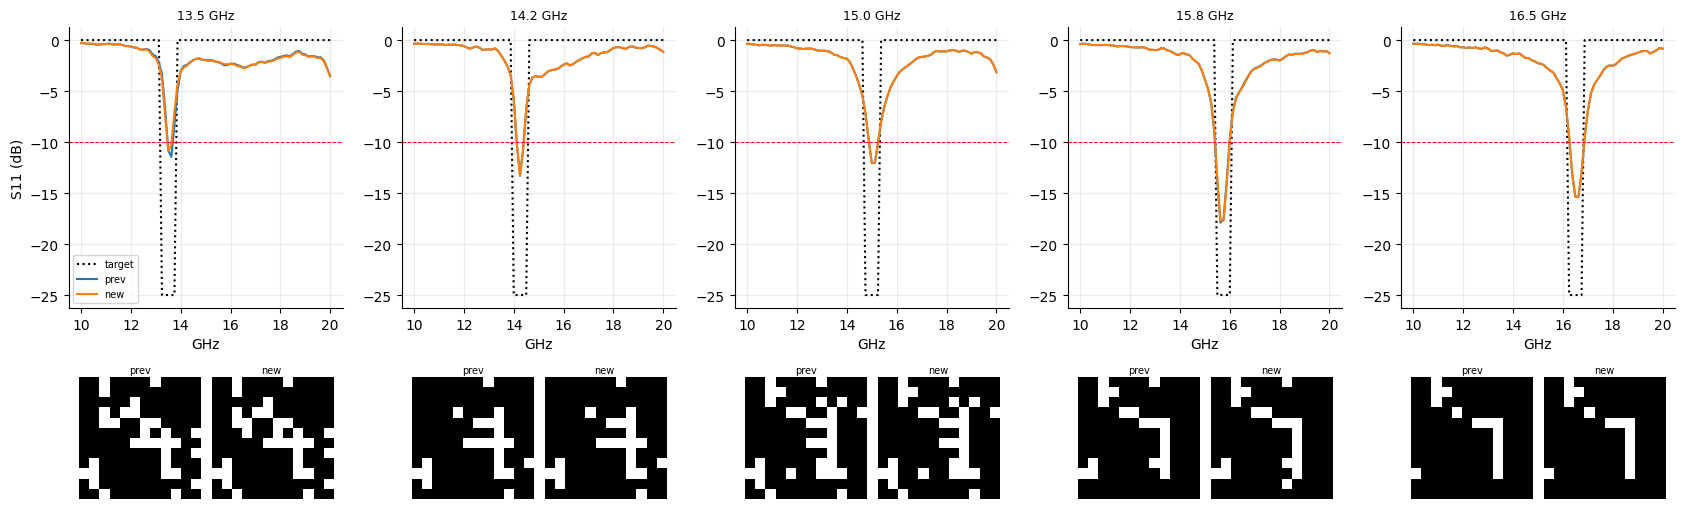

In [77]:
Tem = np.stack([notch_target(c) for c in CFG["EM_TARGETS"]])
rows = []; curves = {"Frequency_GHz": freq}
for tag, mdl in [("prev", prev_model), ("new", inv)]:
    P, M = predict_spectra(mdl, Tem)
    for i, f0 in enumerate(CFG["EM_TARGETS"]):
        mask = M[i].reshape(12, 12).astype(np.uint8)
        np.savetxt(f"{OUT_DIR}/antenna_mask_{f0:.1f}GHz_{tag}.csv", mask, delimiter=",", fmt="%d")
        rows.append({"model": tag, "target_GHz": f0, "pred_resonance_GHz": freq[P[i].argmin()],
                     "pred_min_S11_dB": P[i].min(), "n_dips": int(n_bands_of(P[i:i+1])[0]), "pixels_ON": int(mask.sum())})
        curves[f"{tag}_{f0:.1f}GHz"] = P[i]
em_df = pd.DataFrame(rows).round(3); em_df.to_csv(f"{OUT_DIR}/inverse_design_em_targets.csv", index=False)
pd.DataFrame(curves).to_csv(f"{OUT_DIR}/inverse_design_em_spectra.csv", index=False)
print(em_df.to_string(index=False))

fig = plt.figure(figsize=(3.4 * len(CFG["EM_TARGETS"]), 5.2)); gs = fig.add_gridspec(2, len(CFG["EM_TARGETS"]), height_ratios=[2.3, 1])
for c, f0 in enumerate(CFG["EM_TARGETS"]):
    ax = fig.add_subplot(gs[0, c]); ax.plot(freq, notch_target(f0), "k:", label="target")
    for tag in ["prev", "new"]: ax.plot(freq, curves[f"{tag}_{f0:.1f}GHz"], label=tag)
    ax.set_title("%.1f GHz" % f0, fontsize=9); ax.set_xlabel("GHz"); ax.axhline(THRESH, color="r", ls="--", lw=0.7)
    if c == 0: ax.set_ylabel("S11 (dB)"); ax.legend(fontsize=7)
    ax2 = fig.add_subplot(gs[1, c])
    mp_ = np.hstack([np.loadtxt(f"{OUT_DIR}/antenna_mask_{f0:.1f}GHz_prev.csv", delimiter=","), np.full((12, 1), np.nan), np.loadtxt(f"{OUT_DIR}/antenna_mask_{f0:.1f}GHz_new.csv", delimiter=",")])
    ax2.imshow(np.ma.masked_invalid(mp_), cmap="Greys", vmin=0, vmax=1, interpolation="nearest"); ax2.axis("off")
    ax2.text(5.5, -0.9, "prev", ha="center", fontsize=7); ax2.text(18.5, -0.9, "new", ha="center", fontsize=7)
save_show("em_targets_predicted_spectra")

In [9]:
summary = {"config": CFG,
           "duplicates": {"rows": int(N), "distinct_masks": int(n_groups), "orig_test_rows_with_mask_in_train": int(leak_test0_tr.sum()),
                          "orig_test_rows_with_mask_in_train_or_val": int(leak_test0.sum()),
                          "orig_test_rows": int(len(test0)), "clean_test_rows": int(len(test_idx))},
           "definitions": {"in_band_resonant": "any S11 <= threshold inside the band", "success": "a predicted dip <= threshold within TOL of the target dip"},
           "subset_train_size": int(len(tr_ids)), "subset_val_size": int(len(va_ids)),
           "select_by": CFG["SELECT_BY"], "best_epoch": int(best_epoch), "best_selection_metric": float(best), "improved_over_start": bool(improved),
           "loss_components_start_vs_best": json.loads(chk.reset_index().to_json(orient="records")),
           "spearman_density_vs_success_prev": float(rho),
           "bootstrap_success_change_pp": {k: [float(x) for x in v] for k, v in boot.items()},
           "comparison": json.loads(cmp_df.reset_index().to_json(orient="records"))}
with open(f"{OUT_DIR}/summary.json", "w") as f: json.dump(summary, f, indent=1)

# Optional: back up the new checkpoint on your private Hugging Face repo (Kaggle sessions are temporary)
if HF_UPLOAD_REPO:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"], check=True)
    from getpass import getpass
    from huggingface_hub import HfApi
    api = HfApi(token=getpass("HF WRITE token: ")); api.create_repo(HF_UPLOAD_REPO, repo_type="model", private=True, exist_ok=True)
    api.upload_file(path_or_fileobj=save_path, path_in_repo="inverse_inband_finetuned.pth", repo_id=HF_UPLOAD_REPO, repo_type="model")
    print("Uploaded to https://huggingface.co/" + HF_UPLOAD_REPO)

zip_path = shutil.make_archive(f"{WORK}/inband_finetune_results", "zip", OUT_DIR)
print("Everything is saved in:", OUT_DIR); print("One zip to download:", zip_path)
print(sorted(os.listdir(OUT_DIR)))

NameError: name 'N' is not defined

In [8]:
NEW_PATH = "/kaggle/input/models/ayushvairagade/v3/pytorch/default/1/inverse_inband_finetuned (1).pth"
inv, ck = load_inverse(NEW_PATH)
print("new model | saved epoch:", ck.get("epoch"), "| val loss:", ck.get("val_loss"))

@torch.inference_mode()
def predict_spectra(model, S, bs=1024):
    model.eval(); P, M = [], []
    for i in range(0, len(S), bs):
        s = torch.from_numpy(np.ascontiguousarray(S[i:i+bs])).to(device)
        m = (model(s) >= 0.5).float()
        P.append(fwd(m.reshape(-1, 1, 12, 12)).cpu().numpy()); M.append(m.cpu().numpy())
    return np.concatenate(P), np.concatenate(M)

def notch_target(c):
    s = np.full(81, CFG["BASE_DB"], dtype=np.float32)
    s[np.abs(freq - c) <= CFG["NOTCH_GHZ"] / 2 + 1e-9] = CFG["DEPTH_DB"]
    return s

SHIFT = 0.375
SHIFT_TARGETS = [13.5, 13.75, 14.0, 14.25, 14.5, 14.75, 15.25, 15.5, 15.75]

req = [t + SHIFT for t in SHIFT_TARGETS]
P, M = predict_spectra(inv, np.stack([notch_target(c) for c in req]))
rows = []
for i, t in enumerate(SHIFT_TARGETS):
    mask = M[i].reshape(12, 12).astype(np.uint8)
    np.savetxt(f"{OUT_DIR}/antenna_mask_{t:.1f}GHz_shift.csv", mask, delimiter=",", fmt="%d")
    old_f = f"{OUT_DIR}/antenna_mask_{t:.1f}GHz_new.csv"
    same = bool(os.path.exists(old_f) and np.array_equal(np.loadtxt(old_f, delimiter=","), mask))
    rows.append({"real_target": t, "requested": req[i], "surrogate_res_GHz": freq[P[i].argmin()],
                 "surrogate_min_dB": round(float(P[i].min()), 2), "pixels_ON": int(mask.sum()), "same_as_unshifted": same})
print(pd.DataFrame(rows).to_string(index=False))

new model | saved epoch: 25 | val loss: 4.752738349914551
 real_target  requested  surrogate_res_GHz  surrogate_min_dB  pixels_ON  same_as_unshifted
       13.50     13.875             13.875            -12.06        113              False
       13.75     14.125             14.125            -12.76        119              False
       14.00     14.375             14.250            -12.84        121              False
       14.25     14.625             14.625            -14.21        122              False
       14.50     14.875             14.875            -14.58        122              False
       14.75     15.125             15.250            -16.39        120              False
       15.25     15.625             15.625            -17.90        125              False
       15.50     15.875             15.750            -17.72        124              False
       15.75     16.125             16.000            -18.39        128              False


## What to report (and what not to claim)
- **Scope:** this fine-tuning targets 13-17 GHz. Quote results for that band, and show the outside-band numbers too (any drop there is the price of specialising).
- **Leak-free test set:** every number in sections 6-10 comes from the test set in which no mask occurs in the original train/val split. The numbers from the earlier notebooks were computed on the original test split, so expect them to differ. Section 9 ("How much did the duplicate leakage inflate...") quantifies the difference.
- **Definitions:** in-band = any dip <= -10 dB inside 13-17 GHz; success = a predicted dip <= -10 dB within +-0.25 GHz of the target dip. `legacy_success_%` keeps the old global-minimum rule so you can relate the two.
- **Metric:** success is measured with the frozen forward model on real test spectra and on the Fig. 9-style notch sweep. It is **not** an EM result. Simulate a handful of the exported masks in MATLAB before saying anything about real antennas.
- **Loss components:** the table after training shows whether the *spectrum* (soft and hard-mask) improved or only the design/binary terms did.
- **Evidence for the paper's claim:** section 5 (histogram) and section 6 (density vs success, Spearman correlation) tell you whether the failures follow the sparse bins on your data. Report what you find, even if it only partly agrees with the paper. Check the paper's Fig. 9 before quoting which frequency ranges fail.
- **Before the viva:** (1) the mask orientation/encoding audit against the MATLAB geometry code (the forward-model alignment check in section 7 is a first hint, not a proof); (2) the confidence interval in section 9 (a small improvement with an interval that includes 0 is not an improvement); (3) the leakage-effect table.